# Auditoria das medidas DAX do CanaVis (Etapa 2)

**Notebook:** `notebooks/05_auditoria_medidas_dax.ipynb`
**Escopo desta rodada:** APENAS **auditar, reproduzir, diagnosticar, documentar e PROPOR**.
Nenhuma linha de `powerbi/modelo.tmdl` ou `powerbi/canavis.pbix` e alterada aqui. Todo ajuste de DAX
que eventualmente apareca entra como **proposta** ("sugestao, nao aplicada"); a decisao de aplicar e do time
depois de ler o relatorio `docs/entrega-etapa2/auditoria-medidas-dax.md`.

## Objetivo

A colega Alex pediu a revisao de cinco medidas, verificando se estao sendo calculadas corretamente num
dashboard cuja perspectiva e **"Paraiba vs outros estados"**:

1. **Produtividade** (`fato_producao`)
2. **Participacao regional** (`fato_producao`)
3. **Desvio vs selecao** (`fato_producao`)
4. **Desvio vs grupo** (`fato_producao`)
5. **Vendas etanol** — UF (`fato_vendas_etanol_uf`) e municipios validados (`fato_vendas_etanol_municipio`)

Para cada medida seguimos uma estrutura fixa de seis subpartes:

1. **Definicao atual** — DAX real colado de `powerbi/modelo.tmdl` e explicado termo a termo em pt-BR.
2. **Reproducao em pandas** em tres cenarios de contexto de filtro.
3. **Casos de teste numericos** com os numeros reais da gold (conferidos com `assert`).
4. **Diagnostico** rotulado `CORRETA` / `CORRETA-COM-RESSALVA` / `TEM PROBLEMA`, com evidencia numerica.
5. **Interpretacao e uso no Power BI**.
6. **Fundamentacao** na literatura brasileira/estatistica, com links.

## Ancoragem (decisoes e docs ja escritos)

- **ADR 0002** (`docs/decisoes/0002-fontes-publicas.md`): CONAB (`fato_industria`) so existe no nivel **UF**.
- **ADR 0006** (`docs/decisoes/0006-tiers-de-comparacao-por-clusterizacao.md`): `tier` so e definido nas 27 UFs;
  **Paraiba = `media escala`**.
- **ADR 0008** (`docs/decisoes/0008-tratamento-etapa2.md`): **zero != ausente**. `NaN` = "nao reportado",
  nunca coagido a zero; zero so quando a fonte afirma zero. As colunas `situacao_quantidade`/`situacao_area`
  classificam cada parcela (`presente`, `sem_producao`, `suprimido`).
- `docs/entrega-etapa2/modelo-dados.md` e `docs/entrega-etapa2/medidas-industriais.md`: regras das medidas,
  numeros de referencia e a validacao executada no Power BI Desktop.

> **Regra de ouro desta auditoria:** toda afirmacao numerica abaixo e reproduzida da gold real
> (`data/processed/*.parquet`). Se a gold mudar, os `assert` de sanidade quebram alto, de proposito.


In [1]:
# Bloco A.2 - imports, leitura da gold e asserts de sanidade.
# Executar a partir de notebooks/: a gold fica em ../data/processed.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # noqa: F401  (usado nas secoes visuais da FEAT seguinte)
from pathlib import Path

pd.set_option("display.float_format", lambda v: f"{v:,.10f}")

PROC = Path("../data/processed")

fato_producao = pd.read_parquet(PROC / "fato_producao.parquet")
fato_industria = pd.read_parquet(PROC / "fato_industria.parquet")
fato_vendas_uf = pd.read_parquet(PROC / "fato_vendas_etanol_uf.parquet")
fato_vendas_mun = pd.read_parquet(PROC / "fato_vendas_etanol_municipio.parquet")
dim_territorio = pd.read_parquet(PROC / "dim_territorio.parquet")

# ---- Asserts de sanidade: reproduzem os numeros-chave; falham alto se a gold mudar. ----

# fato_producao: 5.733 linhas x 17 colunas, tres niveis sobrepostos.
assert fato_producao.shape == (5733, 17), fato_producao.shape
assert fato_producao["nivel_territorial"].value_counts().to_dict() == {
    "municipio": 4683,
    "uf": 567,
    "microrregiao": 483,
}
# situacao_* classifica cada parcela (ADR 0008): presente / sem_producao / suprimido.
assert fato_producao["situacao_quantidade"].value_counts().to_dict() == {
    "sem_producao": 3036,
    "presente": 2671,
    "suprimido": 26,
}

# dim_territorio: 273 linhas; tier so nas 27 UFs; PB = uf:25, tier 'media escala'.
assert dim_territorio.shape[0] == 273
assert dim_territorio["nivel_territorial"].value_counts().to_dict() == {
    "municipio": 223,
    "uf": 27,
    "microrregiao": 23,
}
tier_por_nivel = (
    dim_territorio.groupby("nivel_territorial")["tier"].apply(lambda s: int(s.notna().sum())).to_dict()
)
assert tier_por_nivel == {"microrregiao": 0, "municipio": 0, "uf": 27}, tier_por_nivel
pb = dim_territorio.loc[dim_territorio["territorio_id"] == "uf:25"].iloc[0]
assert pb["nome_territorio"] == "Paraíba" and pb["tier"] == "media escala"

# CONAB (fato_industria): so nivel uf, 470 linhas, 24 UFs, 22 safras, sem coluna ano_referencia.
assert fato_industria.shape[0] == 470
assert fato_industria["territorio_id"].str.split(":").str[0].unique().tolist() == ["uf"]
assert fato_industria["territorio_id"].nunique() == 24
assert fato_industria["safra"].nunique() == 22
assert "ano_referencia" not in fato_industria.columns
assert int(fato_industria["ano_alinhamento"].max()) == 2026
# Perfil de ausencia/zeros (zero != ausente): base das secoes de cobertura da FEAT seguinte.
assert fato_industria["producao_acucar_mil_t"].isna().sum() == 7
assert (fato_industria["producao_acucar_mil_t"] == 0).sum() == 71
assert (fato_industria["producao_etanol_total_mil_l"] == 0).sum() == 6
assert (fato_industria["cana_mil_t"] == 0).sum() == 4
assert (fato_industria["atr_kg_t"] == 0).sum() == 6

# Vendas municipais: status_chave; so PB conferida tem territorio_id preenchido.
assert fato_vendas_mun["status_chave"].value_counts().to_dict() == {
    "nao_validada_fora_pb": 148244,
    "codigo_nome_conferidos_pb": 3581,
    "divergente_ou_sem_correspondencia": 1269,
}

print("Asserts de sanidade OK. Formas das tabelas:")
for nome, df in [
    ("fato_producao", fato_producao),
    ("fato_industria", fato_industria),
    ("fato_vendas_etanol_uf", fato_vendas_uf),
    ("fato_vendas_etanol_municipio", fato_vendas_mun),
    ("dim_territorio", dim_territorio),
]:
    print(f"  {nome:32s} {df.shape}")


Asserts de sanidade OK. Formas das tabelas:
  fato_producao                    (5733, 17)
  fato_industria                   (470, 17)
  fato_vendas_etanol_uf            (945, 7)
  fato_vendas_etanol_municipio     (153094, 11)
  dim_territorio                   (273, 13)


In [2]:
# Bloco A.3 - helpers puros que reproduzem o DAX das medidas em pandas.
# Cada funcao tem docstring citando o trecho de DAX que replica. Vivem no notebook
# e sao reutilizados pela secao/FEAT seguinte. Convencao: NaN = ausente, nunca zero.

NIVEL = "nivel_territorial"
Q = "quantidade_produzida_t"
A = "area_colhida_ha"


def nivel_unico(df: pd.DataFrame) -> bool:
    """Emula HASONEVALUE(dim_territorio[nivel_territorial]).

    Verdadeiro quando o contexto de filtro deixa exatamente UM nivel territorial
    visivel. No DAX de 'Produtividade': IF(HASONEVALUE(dim_territorio[nivel_territorial]) && ...).
    """
    return df[NIVEL].nunique(dropna=False) == 1


def tem_parcela_ausente(df: pd.DataFrame, colunas) -> bool:
    """Emula COUNTROWS(FILTER(fato, ISBLANK(col) || ...)) > 0.

    Verdadeiro se qualquer linha do contexto tem valor ausente (NaN) em alguma
    das colunas exigidas. No DAX, essa guarda invalida o agregado inteiro.
    """
    sub = df[list(colunas)]
    return bool(sub.isna().any(axis=1).any())


def produtividade(df: pd.DataFrame) -> float:
    """Emula a medida 'Produtividade':

    IF(HASONEVALUE(dim_territorio[nivel_territorial])
       && COUNTROWS(FILTER(fato_producao,
            ISBLANK(quantidade_produzida_t) || ISBLANK(area_colhida_ha))) = 0,
       DIVIDE(SUM(quantidade_produzida_t), SUM(area_colhida_ha)))

    Razao de agregados (media ponderada), NUNCA media das produtividades.
    Retorna NaN quando: nivel nao e unico, ha parcela ausente, ou DIVIDE protege
    denominador zero (area total 0). 'suprimido' aparece como NaN na gold, logo
    a guarda de ausencia ja o exclui do agregado.
    """
    if not nivel_unico(df):
        return np.nan
    if tem_parcela_ausente(df, (Q, A)):
        return np.nan
    soma_area = df[A].sum()
    if soma_area == 0:  # DIVIDE protege denominador zero -> BLANK
        return np.nan
    return df[Q].sum() / soma_area


def participacao(df_sel: pd.DataFrame, df_nivel: pd.DataFrame) -> float:
    """Emula a medida 'Participacao regional':

    numerador = SUM(q) do territorio selecionado (BLANK se houver parcela ausente);
    denominador = CALCULATE(SUM(q), ALL(dim_territorio), nivel_territorial = Nivel)
    (total do MESMO nivel, tambem BLANK se houver parcela ausente).
    Exige nivel unico na selecao (SELECTEDVALUE(nivel) nao-BLANK).

    df_sel  = fato ja filtrado pela selecao (ex.: PB, ano, fonte).
    df_nivel = fato filtrado pelo mesmo nivel e demais filtros, mas sobre ALL(territorio)
               (ex.: TODAS as UFs do ano) -> o denominador.
    """
    if df_sel[NIVEL].nunique(dropna=False) != 1:
        return np.nan  # SELECTEDVALUE(nivel) = BLANK
    if tem_parcela_ausente(df_sel, (Q,)):
        return np.nan
    if tem_parcela_ausente(df_nivel, (Q,)):
        return np.nan
    total = df_nivel[Q].sum()
    if total == 0:
        return np.nan
    return df_sel[Q].sum() / total


def desvio(atual: float, referencia: float) -> float:
    """Emula o padrao de desvio:

    IF(NOT ISBLANK(Atual) && NOT ISBLANK(Referencia), DIVIDE(Atual - Referencia, Referencia)).

    Retorna NaN se qualquer operando for NaN (ausencia nao vira zero) ou se a
    referencia for zero (DIVIDE protegido).
    """
    if pd.isna(atual) or pd.isna(referencia):
        return np.nan
    if referencia == 0:
        return np.nan
    return (atual - referencia) / referencia


def referencia_allselected(df_sel_nivel: pd.DataFrame) -> float:
    """Emula CALCULATE([Produtividade], ALLSELECTED(dim_territorio)) de 'Desvio vs selecao'.

    A referencia e a produtividade (razao de agregados) sobre TODOS os territorios
    da selecao visivel, no mesmo nivel. df_sel_nivel = fato das UFs selecionadas no ano.
    """
    return produtividade(df_sel_nivel)


def referencia_grupo(df_sel_nivel: pd.DataFrame, tier: str) -> float:
    """Emula CALCULATE([Produtividade], ALLSELECTED(dim_territorio),
    KEEPFILTERS(dim_territorio[tier] = Tier)) de 'Desvio vs grupo'.

    Restringe a referencia ao grupo (tier) do territorio atual. Como tier so e
    definido nas 27 UFs, df_sel_nivel precisa vir ja juntado ao tier da dim.
    Fora do nivel UF, tier = NaN -> referencia BLANK (NaN).
    """
    if tier is None or (isinstance(tier, float) and pd.isna(tier)) or pd.isna(tier):
        return np.nan
    grupo = df_sel_nivel.loc[df_sel_nivel["tier"] == tier]
    return produtividade(grupo)


def _ufs_do_nivel(df_fato: pd.DataFrame, ano: int) -> pd.DataFrame:
    """Atalho de teste: fato de producao no nivel uf, para um ano."""
    return df_fato[(df_fato[NIVEL] == "uf") & (df_fato["ano_referencia"] == ano)]


print("Helpers definidos:", [
    "nivel_unico", "tem_parcela_ausente", "produtividade", "participacao",
    "desvio", "referencia_allselected", "referencia_grupo",
])


Helpers definidos: ['nivel_unico', 'tem_parcela_ausente', 'produtividade', 'participacao', 'desvio', 'referencia_allselected', 'referencia_grupo']


## 1. Produtividade

### 1.1 Definicao atual (DAX real)

```dax
Produtividade =
IF(
    HASONEVALUE(dim_territorio[nivel_territorial])
        && COUNTROWS(
            FILTER(
                fato_producao,
                ISBLANK(fato_producao[quantidade_produzida_t])
                    || ISBLANK(fato_producao[area_colhida_ha])
            )
        ) = 0,
    DIVIDE(SUM(fato_producao[quantidade_produzida_t]), SUM(fato_producao[area_colhida_ha]))
)
```

**Leitura termo a termo (pt-BR):**

- `HASONEVALUE(dim_territorio[nivel_territorial])` — so calcula se o contexto deixa **um unico nivel**
  territorial visivel (uf, microrregiao OU municipio). Impede misturar niveis que sao **totais sobrepostos**.
- `COUNTROWS(FILTER(... ISBLANK(quantidade) || ISBLANK(area) ...)) = 0` — **guarda de ausencia**: se qualquer
  linha do contexto tem quantidade ou area **ausente** (`NaN`), o agregado inteiro fica indisponivel. E a
  materializacao do **ADR 0008** (ausencia nao vira zero). As parcelas `suprimido` entram como `NaN` na gold,
  logo sao justamente o que essa guarda barra.
- `DIVIDE(SUM(quantidade), SUM(area))` — **razao de agregados**: soma primeiro as quantidades, soma as areas, e
  so entao divide. E uma **media ponderada** pela area, nao a media das produtividades municipais. `DIVIDE`
  devolve BLANK (vazio) se a area somada for zero, sem erro de divisao.
- Unidade do resultado: **t/ha** (`formatString: 0.00`).


In [3]:
# 1.2 Reproducao em pandas - tres cenarios de contexto de filtro.
ANO = 2023

# (a) Paraiba, nivel UF unico.
pb_uf = fato_producao[
    (fato_producao[NIVEL] == "uf")
    & (fato_producao["ano_referencia"] == ANO)
    & (fato_producao["territorio_id"] == "uf:25")
]
prod_pb = produtividade(pb_uf)

# (b) Todas as UFs (contexto ALLSELECTED = nivel uf unico, varios territorios).
todas_uf = _ufs_do_nivel(fato_producao, ANO)
prod_todas_uf = produtividade(todas_uf)

# (c) Mistura UF + microrregiao + municipio (sem filtro de nivel).
mistura = fato_producao[fato_producao["ano_referencia"] == ANO]
prod_mistura = produtividade(mistura)

print(f"(a) PB UF 2023 .................. {prod_pb:,.10f} t/ha")
print(f"(b) Todas as UFs 2023 (ponderada) {prod_todas_uf:,.10f} t/ha")
print(f"    media SIMPLES das prod. UF ... {todas_uf['produtividade_t_ha'].mean():,.10f} t/ha  (NAO e o que a medida faz)")
print(f"(c) Mistura 3 niveis 2023 ....... {prod_mistura}  (NaN: HASONEVALUE barra nivel nao unico)")


(a) PB UF 2023 .................. 64.6923844485 t/ha
(b) Todas as UFs 2023 (ponderada) 77.9009038820 t/ha
    media SIMPLES das prod. UF ... 61.1388677983 t/ha  (NAO e o que a medida faz)
(c) Mistura 3 niveis 2023 ....... nan  (NaN: HASONEVALUE barra nivel nao unico)


In [4]:
# 1.3 Casos de teste numericos (numeros reais da gold).
ESPERADO_PROD_PB_2023 = 64.6923844485

assert abs(prod_pb - ESPERADO_PROD_PB_2023) < 1e-9, prod_pb
# A medida e ponderada (77,90), nao a media simples (~61,14) das produtividades por UF.
assert abs(prod_todas_uf - 77.9009038820) < 1e-9, prod_todas_uf
assert abs(todas_uf["produtividade_t_ha"].mean() - 61.1388677983) < 1e-9
# Mistura de niveis => NaN (guarda HASONEVALUE).
assert pd.isna(prod_mistura)
print("OK: produtividade PB 2023 =", f"{prod_pb:,.10f}", "t/ha")


OK: produtividade PB 2023 = 64.6923844485 t/ha


### 1.4 Diagnostico: **CORRETA**

- **Razao de agregados confirmada.** Para a PB em 2023: q = 7.066.802 t, area = 109.237 ha →
  7.066.802 / 109.237 = **64,6923844485 t/ha**, exatamente o valor de referencia de `modelo-dados.md`.
- **Ponderada, nao media de razoes.** Sobre todas as UFs de 2023, a razao de agregados da **77,90 t/ha**,
  enquanto a media simples das produtividades por UF daria **61,14 t/ha**. A medida usa a forma correta
  (ponderada pela area): UFs grandes pesam mais, como manda a metodologia de rendimento medio.
- **`suprimido` nao entra como zero.** As 26 parcelas `suprimido` da gold estao com quantidade/area `NaN`;
  a guarda `COUNTROWS(FILTER(... ISBLANK ...))=0` torna o agregado indisponivel sempre que uma delas esta no
  contexto, em vez de somar zero e subestimar a produtividade (ADR 0008).
- **`HASONEVALUE` protege contra mistura de niveis.** No cenario (c), sem filtro de nivel, a medida devolve
  BLANK em vez de um numero sem sentido somando municipio + microrregiao + UF.

**Ressalva de uso (nao e erro da formula):** a protecao depende de o visual deixar **um unico nivel** no
contexto. Num cartao sem o nivel fixado, a medida fica vazia — o que e seguro, mas pode confundir quem espera
um numero. Ver a secao de arquitetura (filtro de nivel) no relatorio.


### 1.5 Interpretacao e uso no Power BI

- **Onde aparece:** ranking de produtividade por UF e cartao de produtividade da PB (pagina "Validacao UF").
- **Como ler:** t de cana por hectare colhido no ano selecionado; quanto maior, mais eficiente a lavoura.
- **O que o filtro de nivel resolve:** fixar `nivel_territorial = uf` garante `HASONEVALUE` verdadeiro e um
  denominador coerente. Sem ele, a medida fica vazia (seguro) mas o visual parece "quebrado".
- **Armadilha:** nunca comparar este numero com uma media simples de produtividades municipais — sao
  grandezas diferentes (ponderada vs nao ponderada).

### 1.6 Fundamentacao

- Rendimento medio como **razao de agregados** (producao total / area total), nao media de razoes, e a
  convencao da [PAM-IBGE — Producao Agricola Municipal, conceitos e metodos](https://www.ibge.gov.br/estatisticas/economicas/agricultura-e-pecuaria/9117-producao-agricola-municipal-culturas-temporarias-e-permanentes.html).
  *Conteudo parafraseado para conformidade de licenciamento.*
- Contexto agronomico de rendimento da cana: [Embrapa Agroenergia](https://www.embrapa.br/agencia-de-informacao-tecnologica/tematicas/agroenergia/alcool).


## 2. Participacao regional

### 2.1 Definicao atual (DAX real)

```dax
Participação regional =
VAR Nivel = SELECTEDVALUE(dim_territorio[nivel_territorial])
VAR Quantidade =
    IF(COUNTROWS(FILTER(fato_producao, ISBLANK(fato_producao[quantidade_produzida_t]))) = 0,
       SUM(fato_producao[quantidade_produzida_t]))
VAR Total =
    CALCULATE(
        IF(COUNTROWS(FILTER(fato_producao, ISBLANK(fato_producao[quantidade_produzida_t]))) = 0,
           SUM(fato_producao[quantidade_produzida_t])),
        ALL(dim_territorio),
        dim_territorio[nivel_territorial] = Nivel
    )
RETURN IF(NOT ISBLANK(Nivel) && NOT ISBLANK(Quantidade), DIVIDE(Quantidade, Total))
```

**Leitura termo a termo (pt-BR):**

- `SELECTEDVALUE(dim_territorio[nivel_territorial])` — pega o **unico** nivel visivel; se houver mais de um,
  devolve BLANK e a medida nao calcula.
- `Quantidade` — producao do territorio selecionado, **com a mesma guarda de ausencia** (BLANK se alguma
  parcela do contexto tem quantidade `NaN`).
- `Total` com `CALCULATE(..., ALL(dim_territorio), dim_territorio[nivel_territorial] = Nivel)` — **remove** o
  filtro de territorio (`ALL`) mas **reimpoe o mesmo nivel**: o denominador e o total **daquele nivel**
  (ex.: soma de todas as UFs), preservando ano e fonte. Tambem exige completude (sem `NaN`).
- `DIVIDE(Quantidade, Total)` — razao protegida contra denominador zero.
- Unidade: **percentual** (`formatString: 0.00%`).


In [5]:
# 2.2 Reproducao em pandas - tres cenarios.
# (a) PB no total das UFs (denominador = todas as UFs do ano, mesmo nivel).
part_pb = participacao(pb_uf, todas_uf)

# (b) Contexto "todas as UFs" como selecao unica: cada UF sobre o total UF.
#     Para a propria soma de todas as UFs a participacao e 100%.
part_total_uf = participacao(todas_uf, todas_uf)

# (c) Mistura de niveis: numerador sem nivel unico -> BLANK (SELECTEDVALUE vira BLANK).
part_mistura = participacao(mistura, mistura)

print(f"(a) Participacao PB no total UF 2023 . {part_pb*100:,.10f}%")
print(f"(b) Soma de todas as UFs sobre total . {part_total_uf*100:,.4f}%  (100% por definicao)")
print(f"(c) Mistura de niveis ............... {part_mistura}  (NaN: nivel nao unico)")


(a) Participacao PB no total UF 2023 . 0.9036158274%
(b) Soma de todas as UFs sobre total . 100.0000%  (100% por definicao)
(c) Mistura de niveis ............... nan  (NaN: nivel nao unico)


In [6]:
# 2.3 Casos de teste numericos.
ESPERADO_PART_PB_2023 = 0.009036158274  # 0,9036158274%

assert abs(part_pb - ESPERADO_PART_PB_2023) < 1e-12, part_pb
assert abs(part_total_uf - 1.0) < 1e-12
assert pd.isna(part_mistura)
print("OK: participacao PB 2023 =", f"{part_pb*100:,.10f}%")


OK: participacao PB 2023 = 0.9036158274%


In [7]:
# 2.3b Evidencia da MISTURA DE NIVEIS: somar os tres niveis da PB passa de 100%.
# Cada nivel e um TOTAL SOBREPOSTO do mesmo fenomeno; somar duplica a producao da PB.
f23 = fato_producao[fato_producao["ano_referencia"] == ANO]
total_uf_2023 = f23.loc[f23[NIVEL] == "uf", Q].sum()
micro_pb_2023 = f23.loc[(f23[NIVEL] == "microrregiao") & f23["territorio_id"].str.startswith("microrregiao:25"), Q].sum()
mun_pb_2023 = f23.loc[(f23[NIVEL] == "municipio") & f23["territorio_id"].str.startswith("municipio:25"), Q].sum()
soma_tres_niveis = total_uf_2023 + micro_pb_2023 + mun_pb_2023
pct_sobre_total_uf = soma_tres_niveis / total_uf_2023 * 100

print(f"Total UF 2023 ............. {total_uf_2023:,.0f} t")
print(f"+ microrregioes PB ....... {micro_pb_2023:,.0f} t")
print(f"+ municipios PB .......... {mun_pb_2023:,.0f} t")
print(f"= soma CEGA dos 3 niveis . {soma_tres_niveis:,.0f} t = {pct_sobre_total_uf:,.1f}% do total UF verdadeiro")
assert abs(pct_sobre_total_uf - 101.8) < 0.05, pct_sobre_total_uf
print("-> A soma passa de 100% porque micro e municipio PB repetem producao ja contida no total UF.")


Total UF 2023 ............. 782,058,236 t
+ microrregioes PB ....... 7,066,802 t
+ municipios PB .......... 7,066,802 t
= soma CEGA dos 3 niveis . 796,191,840 t = 101.8% do total UF verdadeiro
-> A soma passa de 100% porque micro e municipio PB repetem producao ja contida no total UF.


### 2.4 Diagnostico: **CORRETA-COM-RESSALVA**

- **A formula esta correta** e bem protegida: PB em 2023 = **0,9036158274%** do total das 27 UFs (denominador
  completo, todas as UFs com `situacao_quantidade = presente`). A guarda de ausencia impede dividir por um
  total parcial, e `SELECTEDVALUE` zera o calculo se o nivel nao for unico.
- **Ressalva (mistura de niveis no visual).** Somar **cegamente** os tres niveis de 2023 (UF + microrregiao PB
  + municipio PB) da **796.191.840 t = 101,8%** do total verdadeiro das UFs — passa de 100% porque
  microrregiao e municipio sao **totais sobrepostos** que repetem a producao da PB ja contida no total UF.
  A medida **se protege** (SELECTEDVALUE vira BLANK sem nivel unico), mas um visual que **nao fixa o nivel**
  ainda engana: um ranking que mistura municipios e UFs perde sentido (percentuais incomparaveis, soma > 100%).
- **Conclusao:** o risco nao esta na expressao DAX, e na **montagem do visual**. O filtro de nivel territorial
  por pagina e hoje obrigatorio. A secao de arquitetura do relatorio propoe tornar isso estrutural.


### 2.5 Interpretacao e uso no Power BI

- **Onde aparece:** "Participacao por UF" — quanto cada UF representa na producao nacional do ano.
- **Como ler:** fatia percentual do territorio no total **do seu nivel**; so faz sentido comparar territorios
  do **mesmo** nivel.
- **O que o filtro de nivel resolve:** sem `nivel_territorial = uf` fixado, a medida fica vazia (protecao) ou,
  num visual mal montado que force agregacao, induz leitura de soma > 100%.
- **Armadilha:** nunca colocar municipio e UF no mesmo eixo de participacao.

### 2.6 Fundamentacao

- Participacao/concentracao regional e o campo do **Quociente Locacional (QL)** da economia regional,
  tratado por [IBGE](https://www.ibge.gov.br/) e [IPEA](https://www.ipea.gov.br/) *(links institucionais;
  pagina de metodologia especifica de QL a confirmar na escrita do relatorio)*. A medida aqui e a forma mais
  simples de participacao (parte sobre o todo do mesmo nivel), base do QL. *Conteudo parafraseado para
  conformidade de licenciamento.*


## 3. Desvio vs selecao

### 3.1 Definicao atual (DAX real)

```dax
Desvio vs seleção =
VAR Atual = [Produtividade]
VAR Referencia = CALCULATE([Produtividade], ALLSELECTED(dim_territorio))
RETURN IF(NOT ISBLANK(Atual) && NOT ISBLANK(Referencia), DIVIDE(Atual - Referencia, Referencia))
```

**Leitura termo a termo (pt-BR):**

- `Atual = [Produtividade]` — reaproveita a medida 1 (ja com todas as guardas de nivel unico e ausencia).
- `CALCULATE([Produtividade], ALLSELECTED(dim_territorio))` — recalcula a produtividade sobre **tudo que o
  usuario deixou selecionado**, ignorando o filtro de uma linha/territorio especifico mas respeitando os
  recortes externos (ano, fonte, segmentacoes). E a **referencia da selecao**. Como reusa `[Produtividade]`,
  tambem e uma razao de agregados (ponderada).
- `IF(NOT ISBLANK(Atual) && NOT ISBLANK(Referencia), ...)` — so calcula com **ambos** presentes: ausencia nao
  vira zero nem desvio de -100%.
- `DIVIDE(Atual - Referencia, Referencia)` — desvio percentual padrao, protegido contra referencia zero.
- Unidade: **percentual** (`formatString: 0.00%`).


In [8]:
# 3.2 Reproducao em pandas - tres cenarios.
# Referencia ALLSELECTED = produtividade ponderada de todas as UFs selecionadas.
ref_sel = referencia_allselected(todas_uf)

# (a) Desvio da PB vs a selecao (todas as UFs).
desvio_pb_sel = desvio(prod_pb, ref_sel)

# (b) Desvio da propria selecao vs ela mesma = 0.
desvio_sel_sel = desvio(prod_todas_uf, ref_sel)

# (c) Mistura de niveis: Atual = BLANK -> desvio BLANK.
desvio_mistura = desvio(produtividade(mistura), referencia_allselected(mistura))

print(f"Referencia ALLSELECTED (todas UF) . {ref_sel:,.10f} t/ha")
print(f"(a) Desvio PB vs selecao .......... {desvio_pb_sel*100:,.10f}%")
print(f"(b) Desvio selecao vs ela mesma ... {desvio_sel_sel*100:,.4f}%")
print(f"(c) Mistura de niveis ............. {desvio_mistura}  (NaN)")


Referencia ALLSELECTED (todas UF) . 77.9009038820 t/ha
(a) Desvio PB vs selecao .......... -16.9555406617%
(b) Desvio selecao vs ela mesma ... 0.0000%
(c) Mistura de niveis ............. nan  (NaN)


In [9]:
# 3.3 Casos de teste numericos.
ESPERADO_DESVIO_SEL_PB = -0.169555406617  # -16,9555406617%

assert abs(ref_sel - 77.9009038820) < 1e-9, ref_sel
assert abs(desvio_pb_sel - ESPERADO_DESVIO_SEL_PB) < 1e-10, desvio_pb_sel
assert abs(desvio_sel_sel) < 1e-12
assert pd.isna(desvio_mistura)
print("OK: desvio vs selecao PB 2023 =", f"{desvio_pb_sel*100:,.10f}%", "(ref", f"{ref_sel:,.10f} t/ha)")


OK: desvio vs selecao PB 2023 = -16.9555406617% (ref 77.9009038820 t/ha)


### 3.4 Diagnostico: **CORRETA-COM-RESSALVA**

- **Numericamente certa.** PB em 2023 fica **-16,9555406617%** abaixo da referencia ponderada das UFs
  (**77,9009038820 t/ha**), coerente com `modelo-dados.md`. A protecao `ISBLANK` evita o bug historico de
  desvio -100% quando a produtividade atual esta ausente (issue #11).
- **Ressalva 1 — `ALLSELECTED` sem nivel fixado.** A referencia depende do que esta **selecionado**. Se o
  visual nao fixa o nivel, `ALLSELECTED(dim_territorio)` pode trazer municipios, microrregioes e UFs juntos,
  produzindo uma referencia com mistura de niveis. Como `[Produtividade]` exige `HASONEVALUE`, na pratica a
  medida acaba BLANK nesse caso (protecao), mas o significado da "referencia" so e claro **com o nivel fixado**.
- **Ressalva 2 — referencia movel.** O numero muda conforme a selecao do usuario. E uma referencia **geral**
  da selecao, nao uma comparacao por pares; nao confundir com o desvio vs grupo (secao 4).


### 3.5 Interpretacao e uso no Power BI

- **Onde aparece:** comparacao geral — quanto a UF difere do conjunto que o usuario deixou selecionado.
- **Como ler:** sinal negativo = abaixo da referencia; positivo = acima. A referencia e a produtividade
  **ponderada** da selecao, nao a media simples.
- **O que o filtro de nivel resolve:** fixar `nivel_territorial = uf` garante que a referencia some "UF contra
  UFs", nao UF contra uma mistura.
- **Armadilha:** como a referencia e movel, documentar sempre **qual** selecao esta ativa ao citar o numero.

### 3.6 Fundamentacao

- Desvio percentual relativo a uma referencia e **estatistica descritiva basica** ((valor - referencia) /
  referencia); nao exige fonte externa. A escolha da referencia como **razao de agregados** da selecao herda a
  mesma fundamentacao da produtividade ([PAM-IBGE](https://www.ibge.gov.br/estatisticas/economicas/agricultura-e-pecuaria/9117-producao-agricola-municipal-culturas-temporarias-e-permanentes.html)).


## 4. Desvio vs grupo

### 4.1 Definicao atual (DAX real)

```dax
Desvio vs grupo =
VAR Tier = SELECTEDVALUE(dim_territorio[tier])
VAR Atual = [Produtividade]
VAR Referencia =
    CALCULATE([Produtividade], ALLSELECTED(dim_territorio),
              KEEPFILTERS(dim_territorio[tier] = Tier))
RETURN IF(NOT ISBLANK(Tier) && NOT ISBLANK(Atual) && NOT ISBLANK(Referencia),
          DIVIDE(Atual - Referencia, Referencia))
```

**Leitura termo a termo (pt-BR):**

- `SELECTEDVALUE(dim_territorio[tier])` — o grupo (tier) do territorio atual. `tier` so e definido nas **27
  UFs** (ADR 0006); microrregiao e municipio tem `tier = NaN`, logo `Tier` vira BLANK fora do nivel UF.
- `ALLSELECTED(dim_territorio)` — base da referencia (tudo selecionado), como na secao 3.
- `KEEPFILTERS(dim_territorio[tier] = Tier)` — **mantem** o filtro de grupo ao expandir: a referencia e a
  produtividade **apenas das UFs do mesmo tier** (ex.: `media escala`), nao de todas as UFs.
- `IF(NOT ISBLANK(Tier) && ...)` — exige tier presente **e** atual **e** referencia presentes; caso contrario
  BLANK. E a razao de a medida ficar vazia fora do nivel UF.
- Unidade: **percentual** (`formatString: 0.00%`).


In [10]:
# 4.2 Reproducao em pandas - tres cenarios.
# Juntar o tier da dim as UFs do ano (tier so existe no nivel uf).
tier_uf = dim_territorio.loc[dim_territorio[NIVEL] == "uf", ["territorio_id", "tier"]]
todas_uf_tier = todas_uf.merge(tier_uf, on="territorio_id", how="left")

tier_pb = dim_territorio.loc[dim_territorio["territorio_id"] == "uf:25", "tier"].iloc[0]

# (a) Desvio da PB vs seu grupo (media escala).
ref_grupo = referencia_grupo(todas_uf_tier, tier_pb)
desvio_pb_grupo = desvio(prod_pb, ref_grupo)

# (b) Quantas UFs no grupo 'media escala'.
n_media_escala = int((tier_uf["tier"] == "media escala").sum())

# (c) Fora do nivel UF (municipio): tier = NaN -> referencia e medida BLANK.
ref_grupo_municipio = referencia_grupo(todas_uf_tier, np.nan)

print(f"Tier da PB ................... {tier_pb!r}")
print(f"UFs no grupo 'media escala' .. {n_media_escala}")
print(f"Referencia do grupo .......... {ref_grupo:,.10f} t/ha")
print(f"(a) Desvio PB vs grupo ....... {desvio_pb_grupo*100:,.10f}%")
print(f"(c) tier NaN (fora de UF) .... {ref_grupo_municipio}  (NaN -> medida BLANK)")


Tier da PB ................... 'media escala'
UFs no grupo 'media escala' .. 14
Referencia do grupo .......... 62.5608197218 t/ha
(a) Desvio PB vs grupo ....... 3.4071879750%
(c) tier NaN (fora de UF) .... nan  (NaN -> medida BLANK)


In [11]:
# 4.3 Casos de teste numericos.
ESPERADO_DESVIO_GRUPO_PB = 0.034071879750  # +3,4071879750%

assert tier_pb == "media escala"
assert n_media_escala == 14, n_media_escala
assert abs(ref_grupo - 62.5608197218) < 1e-9, ref_grupo
assert abs(desvio_pb_grupo - ESPERADO_DESVIO_GRUPO_PB) < 1e-10, desvio_pb_grupo
assert pd.isna(ref_grupo_municipio)
print("OK: desvio vs grupo PB 2023 =", f"{desvio_pb_grupo*100:,.10f}%", "(ref grupo", f"{ref_grupo:,.10f} t/ha)")


OK: desvio vs grupo PB 2023 = 3.4071879750% (ref grupo 62.5608197218 t/ha)


### 4.4 Diagnostico: **CORRETA-COM-RESSALVA**

- **Numericamente certa no nivel UF.** PB (`media escala`, 14 UFs) fica **+3,4071879750%** acima da referencia
  ponderada do grupo (**62,5608197218 t/ha**). Contra a selecao inteira (secao 3) a PB estava **abaixo**;
  contra os pares de escala parecida, esta **acima** — exatamente o valor de comparar com quem e comparavel.
- **Ressalva estrutural — `tier` so existe nas UFs.** Como `tier = NaN` em microrregiao e municipio (ADR 0006),
  a medida retorna **BLANK fora do nivel UF**. Isso e **correto por design** (nao ha grupos definidos nesses
  niveis), mas num visual fora de UF a medida aparece vazia e pode ser lida como erro. A guarda
  `IF(NOT ISBLANK(Tier) && ...)` garante que nunca vira zero ou -100%.
- **Dependencia resolvida.** O `tier` ja esta materializado na gold para as 27 UFs (Task 4 / issue #8), entao
  a comparacao por pares e valida; antes disso a medida retornava vazio por falta da coluna.


### 4.5 Interpretacao e uso no Power BI

- **Onde aparece:** comparacao por pares — quanto a UF difere das UFs **do mesmo porte** (tier por clusterizacao,
  ADR 0006).
- **Como ler:** positivo = acima dos pares de escala semelhante; negativo = abaixo. Mais justo que o desvio vs
  selecao quando o objetivo e "comparar com quem e comparavel".
- **O que o filtro de nivel resolve:** so faz sentido no nivel UF; fora dele a medida fica (corretamente) vazia.
- **Armadilha:** nao interpretar o BLANK fora de UF como "zero" ou "sem diferenca".

### 4.6 Fundamentacao

- Comparar contra o grupo de pares (tier) reduz o vies de escala, no espirito da **analise de concentracao
  regional** ([IBGE](https://www.ibge.gov.br/), [IPEA](https://www.ipea.gov.br/)). A definicao dos tiers por
  clusterizacao esta no [ADR 0006](../docs/decisoes/0006-tiers-de-comparacao-por-clusterizacao.md). O calculo
  do desvio e estatistica descritiva (desvio percentual padrao). *Conteudo parafraseado para conformidade de
  licenciamento.*


## 5. Vendas etanol (UF e municipios validados)

### 5.1 Definicao atual (DAX real)

```dax
Vendas etanol UF (L) =
IF(SELECTEDVALUE(dim_territorio[nivel_territorial]) = "uf",
   SUM(fato_vendas_etanol_uf[vendas_etanol_hidratado_l]))

Vendas etanol municípios validados (L) =
IF(SELECTEDVALUE(dim_territorio[nivel_territorial]) = "municipio",
   SUM(fato_vendas_etanol_municipio[vendas_etanol_hidratado_l]))
```

**Leitura termo a termo (pt-BR):**

- `SELECTEDVALUE(dim_territorio[nivel_territorial]) = "uf"` / `= "municipio"` — cada medida so responde no **seu**
  nivel. Isso impede que as duas representacoes das mesmas vendas sejam somadas no mesmo visual.
- `SUM(...[vendas_etanol_hidratado_l])` — soma simples do volume de etanol hidratado, em **litros**.
- A medida municipal depende do **relacionamento** `fato_vendas_etanol_municipio[territorio_id]` →
  `dim_territorio`. So as linhas com `territorio_id` preenchido (PB conferida, `status_chave =
  codigo_nome_conferidos_pb`) se ligam a um municipio da dimensao; as demais ficam fora do visual municipal.
- Unidade: **litros** (`formatString: #,0`).

> **Nota (ADR 0008 / modelo-dados.md):** nao somar vendas UF com o detalhe municipal — sao duas
> representacoes das MESMAS vendas. O total por UF deve vir da fato de UF, que preserva valores cuja chave
> municipal nao foi validada.


In [12]:
# 5.2 Reproducao em pandas - tres cenarios.
# (a) Vendas UF da PB em 2023 (nivel uf).
vendas_uf_pb = fato_vendas_uf[
    (fato_vendas_uf["territorio_id"] == "uf:25") & (fato_vendas_uf["ano_referencia"] == ANO)
]["vendas_etanol_hidratado_l"].sum()

# (b) Soma dos municipios PB validados em 2023 (nivel municipio, chave conferida).
vm_pb = fato_vendas_mun[(fato_vendas_mun["uf"] == "PB") & (fato_vendas_mun["ano_referencia"] == ANO)]
vendas_mun_pb = vm_pb["vendas_etanol_hidratado_l"].sum()
n_mun_pb = vm_pb["codigo_municipio_origem"].nunique()
status_pb = vm_pb["status_chave"].value_counts().to_dict()

# (c) Linhas fora da PB nao tem territorio_id -> nao entram no visual municipal validado.
sem_territorio = fato_vendas_mun["territorio_id"].isna().sum()
com_territorio = fato_vendas_mun["territorio_id"].notna().sum()

print(f"(a) Vendas UF PB 2023 ............ {vendas_uf_pb:,.0f} L")
print(f"(b) Soma municipios PB 2023 ..... {vendas_mun_pb:,.0f} L  ({n_mun_pb} municipios)")
print(f"    status_chave dos municipios PB: {status_pb}")
print(f"(c) linhas municipais SEM territorio_id (fora da PB): {sem_territorio:,} | COM: {com_territorio:,}")


(a) Vendas UF PB 2023 ............ 126,411,400 L
(b) Soma municipios PB 2023 ..... 126,411,400 L  (159 municipios)
    status_chave dos municipios PB: {'codigo_nome_conferidos_pb': 159}
(c) linhas municipais SEM territorio_id (fora da PB): 149,513 | COM: 3,581


In [13]:
# 5.3 Casos de teste numericos.
ESPERADO_VENDAS_PB_2023 = 126_411_400

assert vendas_uf_pb == ESPERADO_VENDAS_PB_2023, vendas_uf_pb
# A soma municipal validada coincide com o total UF nesse ano: todos os 159 municipios PB
# de 2023 tem status_chave = codigo_nome_conferidos_pb (todos conferidos).
assert vendas_mun_pb == ESPERADO_VENDAS_PB_2023, vendas_mun_pb
assert n_mun_pb == 159, n_mun_pb
assert status_pb == {"codigo_nome_conferidos_pb": 159}, status_pb
print("OK: vendas UF PB 2023 =", f"{vendas_uf_pb:,.0f} L", "| soma municipios PB =", f"{vendas_mun_pb:,.0f} L")


OK: vendas UF PB 2023 = 126,411,400 L | soma municipios PB = 126,411,400 L


### 5.4 Diagnostico: **CORRETA-COM-RESSALVA**

- **Numeros batem.** Vendas UF da PB em 2023 = **126.411.400 L**; a soma dos **159 municipios PB validados**
  do mesmo ano da **exatamente 126.411.400 L**. Coincidem porque, em 2023, **todos** os municipios PB tem
  `status_chave = codigo_nome_conferidos_pb` — a validacao esta completa, entao detalhe municipal e total UF
  conferem.
- **Separacao por nivel correta.** Cada medida so responde no seu nivel (`= "uf"` / `= "municipio"`), evitando
  somar as duas representacoes das mesmas vendas num unico visual (regra do `modelo-dados.md`).
- **Ressalva — cobertura do detalhe municipal.** So linhas com `territorio_id` preenchido (PB conferida) se
  ligam a um municipio da dimensao. Das 153.094 linhas municipais, a imensa maioria (`nao_validada_fora_pb`,
  `divergente_ou_sem_correspondencia`) fica **fora** do visual municipal validado. Isso e **intencional** (so
  a PB foi conferida codigo+nome), mas significa que "Vendas etanol municipios validados" **nao e um total
  nacional** — e so a PB. Fora da PB, usar sempre a medida de **UF**, que preserva o valor mesmo sem chave
  municipal validada.


### 5.5 Interpretacao e uso no Power BI

- **Onde aparece:** consumo comercial de etanol hidratado por UF/ano (medida UF) e por municipio PB validado
  (medida municipal).
- **Como ler:** volume em **litros**. Para total por UF use a medida de UF; o detalhe municipal so e confiavel
  na PB.
- **O que o filtro de nivel resolve:** cada medida ja se auto-restringe ao seu nivel via `SELECTEDVALUE`, entao
  nao ha risco de dupla contagem mesmo sem filtro de pagina; ainda assim, fixar o nivel deixa o visual previsivel.
- **Armadilha:** nao ler "Vendas etanol municipios validados" como total do Brasil — e so a PB conferida.
  Atencao tambem ao `escopo_vendas`: vendas ate 2006 incluem consumo proprio na fonte (ADR 0008).

### 5.6 Fundamentacao

- As vendas vem da serie da ANP. A distincao entre o agregado por UF e o detalhe municipal (com validacao de
  chave codigo+nome) segue o principio **zero != ausente / chave nao validada != municipio conhecido** do
  [ADR 0008](../docs/decisoes/0008-tratamento-etapa2.md). Soma simples de volumes em litros e agregacao direta
  (sem razao), entao a fundamentacao estatistica e a de totalizacao de contagem/volume. *Conteudo parafraseado
  para conformidade de licenciamento.*


## Encerramento (FEAT-001)

Esta rodada estabeleceu o notebook (Bloco A: setup + helpers) e auditou as cinco medidas (Bloco B), cada uma
com DAX real, reproducao em tres cenarios, casos de teste numericos conferidos, diagnostico rotulado,
interpretacao de uso e fundamentacao. Resumo dos vereditos:

| Medida | Veredito | Evidencia-chave |
|---|---|---|
| Produtividade | CORRETA | 64,6923844485 t/ha (ponderada 77,90 vs media simples 61,14) |
| Participacao regional | CORRETA-COM-RESSALVA | PB 0,9036158274%; soma cega dos 3 niveis = 101,8% |
| Desvio vs selecao | CORRETA-COM-RESSALVA | -16,9555406617% (ref ALLSELECTED 77,9009038820) |
| Desvio vs grupo | CORRETA-COM-RESSALVA | +3,4071879750% (ref grupo `media escala` 62,5608197218) |
| Vendas etanol (UF/municipios) | CORRETA-COM-RESSALVA | 126.411.400 L (UF = soma municipal PB validada) |

As secoes de volume/mix (ATR-equivalente, cobertura CONAB) e a secao de arquitetura do filtro de nivel ficam
para a FEAT seguinte, que reutiliza os helpers definidos no Bloco A.3. **Nenhum ajuste foi aplicado ao modelo
Power BI**; propostas de DAX, se houver, vivem no relatorio como "sugestao, nao aplicada".


## 6. Indicadores de volume e composicao do mix (cana -> acucar + etanol)

**Bloco C.** As cinco medidas auditadas acima e os indicadores industriais ja existentes
(`Mix etanol acucar (L por t)`, `Intensidade acucar (t por t)`, `ATR ponderado (kg por t)`)
sao **razoes**: comprimem duas quantidades numa unica escala. O usuario pediu (correcao #1) uma
visao que compare **visualmente as quantidades** de acucar, etanol e cana **sem reduzir a uma razao
unitaria** — mostrar quanto de cada produto foi feito, lado a lado, em uma base comparavel.

**Base comparavel = ATR-equivalente.** Acucar vem em mil toneladas e etanol em mil litros; as duas
quantidades **nao somam nem empilham diretamente** (unidades fisicas distintas). O padrao setorial
brasileiro para colocar ambos na mesma regua e o **ATR (Acucar Total Recuperavel)**, a base de
pagamento do sistema CONSECANA: cada quilo de acucar e cada litro de etanol tem um fator de conversao
para "kg de ATR". Convertendo os dois produtos para ATR-equivalente, a composicao do destino da cana
(quanto virou acucar, quanto virou etanol) passa a ser comparavel e somavel.

**Escopo = so nivel UF.** A fonte desses dados e a CONAB (`fato_industria`), que so publica no nivel
estadual (ADR 0002 — CONAB nao chega a municipio nem microrregiao). Isso tem um efeito colateral util
para o problema de arquitetura (Bloco D): **no nivel UF a "dor" do filtro de nivel territorial some**,
porque so existe um nivel. Todos os indicadores de volume/mix sao, por construcao, exclusivos da tela
de UF.

> **Regra de ouro desta secao:** quantidade e volume, nao razao. A razao responde "quantos litros de
> etanol por tonelada de acucar"; o volume/share responde "deste total de cana, que fracao virou cada
> produto". Sao perguntas diferentes e complementares.

In [14]:
# 6.1 Helpers de ATR-equivalente e tratamento de ausencia (vivem no notebook).
# Fatores de conversao em ATR do sistema CONSECANA-SP (padrao setorial brasileiro).
# Fonte tecnica que reproduz os fatores oficiais:
#   Piracicaba Engenharia - "Resumo das formulas de rendimentos e eficiencia
#   utilizadas na industria acucareira"
#   https://www.piracicabaengenharia.com.br/resumo-das-formulas-de-rendimentos-e-eficiencia-utilizadas-na-industria-acucareira/
#   Sistema: https://www.consecana.com.br/   (conteudo parafraseado p/ conformidade de licenciamento)
F_ACUCAR_BRANCO = 1.0495   # kg ATR por kg de acucar branco
F_ACUCAR_VHP    = 1.0453   # kg ATR por kg de acucar VHP (alternativa sensivel)
F_AH            = 1.6913   # kg ATR por litro de alcool (etanol) HIDRATADO
F_AA            = 1.7651   # kg ATR por litro de alcool (etanol) ANIDRO

# PREMISSA A CONFIRMAR: a CONAB informa "acucar" generico, sem distinguir branco vs VHP.
# Adotamos o acucar branco (1,0495) como premissa; VHP (1,0453) como alternativa. A escolha
# muda o share do acucar em menos de 0,5 ponto percentual (os fatores diferem ~0,4%), entao
# nao altera nenhuma conclusao qualitativa. Marcado "a confirmar" em vez de inventar certeza.
F_ACUCAR = F_ACUCAR_BRANCO

# Unidades da gold: acucar em MIL TONELADAS (1 mil t = 1e6 kg); etanol em MIL LITROS (1 mil L = 1e3 L).
# Os fatores sao por kg (acucar) e por litro (etanol), entao normalizamos as unidades ANTES de aplicar.
KG_POR_MIL_T = 1e6
L_POR_MIL_L  = 1e3


def atr_equivalente_acucar(acucar_mil_t: float) -> float:
    """ATR-equivalente do acucar, em kg de ATR. acucar_mil_t -> kg -> * fator CONSECANA.
    Retorna NaN se o insumo for NaN (ausencia NUNCA coagida a zero; ADR 0008)."""
    if pd.isna(acucar_mil_t):
        return np.nan
    return acucar_mil_t * KG_POR_MIL_T * F_ACUCAR


def atr_equivalente_etanol(anidro_mil_l: float, hidratado_mil_l: float) -> float:
    """ATR-equivalente do etanol, em kg de ATR, usando anidro e hidratado SEPARADOS
    (fatores distintos: 1,7651 vs 1,6913). NUNCA usar so o total, que mistura os dois.
    Retorna NaN se QUALQUER insumo necessario for NaN (ausencia nunca vira zero)."""
    if pd.isna(anidro_mil_l) or pd.isna(hidratado_mil_l):
        return np.nan
    return anidro_mil_l * L_POR_MIL_L * F_AA + hidratado_mil_l * L_POR_MIL_L * F_AH


def classificar_uf_safra(row) -> str:
    """Classifica uma linha UF-safra para o comparativo de volume/mix (ADR 0008):
      - 'sem_dado'  : cana ausente/zero (nao processou) OU acucar/etanol nao reportados (NaN)
                      -> fora do visual daquela safra, NUNCA plotado como zero;
      - 'mix_real'  : cana>0 e algum produto == 0 de forma legitima (ex.: TO 100% etanol,
                      acucar=0 COM cana>0) -> a fatia zero e informacao, nao lacuna;
      - 'presente'  : cana>0 e acucar e etanol reportados e > 0.
    Regra: zero != ausente. NaN sempre 'nao reportado'; zero so quando a fonte afirma zero."""
    cana = row["cana_mil_t"]
    ac = row["producao_acucar_mil_t"]
    an = row["producao_etanol_anidro_mil_l"]
    hi = row["producao_etanol_hidratado_mil_l"]
    # Sem dado: cana ausente ou zero (nao processou), ou produtos nao reportados.
    if pd.isna(cana) or cana == 0:
        return "sem_dado"
    if pd.isna(ac) or pd.isna(an) or pd.isna(hi):
        return "sem_dado"
    # A partir daqui cana>0 e produtos reportados. Produto==0 COM cana>0 = mix real.
    if ac == 0 or (an == 0 and hi == 0):
        return "mix_real"
    return "presente"


def share_atr(atr_ac: float, atr_et: float) -> float:
    """Share do ACUCAR no destino da cana, em ATR-equivalente: atr_ac / (atr_ac + atr_et).
    DIVIDE protegido: denominador zero ou NaN -> 'INDEFINIDO' (NaN), NUNCA 0% nem 50/50.
    Mono-produto legitimo (ex.: acucar=0, etanol>0) retorna 0,0 sem divisao por zero."""
    if pd.isna(atr_ac) or pd.isna(atr_et):
        return np.nan
    denom = atr_ac + atr_et
    if denom == 0:  # ATR reconstruido total zero (6 UF-safra atr=0) -> sem informacao
        return np.nan
    return atr_ac / denom


# Enriquecer fato_industria com as colunas derivadas (nao toca a gold em disco).
ind = fato_industria.copy()
ind["atr_eq_acucar"] = ind["producao_acucar_mil_t"].map(atr_equivalente_acucar)
ind["atr_eq_etanol"] = ind.apply(
    lambda r: atr_equivalente_etanol(
        r["producao_etanol_anidro_mil_l"], r["producao_etanol_hidratado_mil_l"]
    ),
    axis=1,
)
ind["situacao_mix"] = ind.apply(classificar_uf_safra, axis=1)
ind["share_acucar_atr"] = ind.apply(
    lambda r: share_atr(r["atr_eq_acucar"], r["atr_eq_etanol"]), axis=1
)
ind["share_etanol_atr"] = 1 - ind["share_acucar_atr"]

# Validacao da receita (prototipada no plano): PB 2023/24 share acucar ~27,5%; TO 100% etanol;
# RO 2019/20 (cana=0) INDEFINIDO.
_pb = ind[(ind["territorio_id"] == "uf:25") & (ind["safra"] == "2023/24")].iloc[0]
print(f"PB 2023/24  share acucar (ATR) = {_pb['share_acucar_atr'] * 100:.2f}%  "
      f"situacao={_pb['situacao_mix']}")
_to = ind[(ind["uf"] == "TO") & (ind["safra"] == "2023/24")]
if len(_to):
    r = _to.iloc[0]
    print(f"TO 2023/24  share acucar (ATR) = {r['share_acucar_atr'] * 100:.2f}%  "
          f"situacao={r['situacao_mix']} (mono-etanol: acucar=0 COM cana>0)")
_ro = ind[(ind["uf"] == "RO") & (ind["safra"] == "2019/20")].iloc[0]
print(f"RO 2019/20  share acucar (ATR) = {_ro['share_acucar_atr']}  "
      f"situacao={_ro['situacao_mix']} (cana=0 -> INDEFINIDO/NaN, nunca 0% nem 50/50)")

assert abs(_pb["share_acucar_atr"] - 0.275373) < 1e-4, _pb["share_acucar_atr"]
assert _to.iloc[0]["share_acucar_atr"] == 0.0 and _to.iloc[0]["situacao_mix"] == "mix_real"
assert pd.isna(_ro["share_acucar_atr"]) and _ro["situacao_mix"] == "sem_dado"
print("\nHelpers de ATR-equivalente OK (premissa de fator do acucar: branco 1,0495 - a confirmar).")

PB 2023/24  share acucar (ATR) = 27.54%  situacao=presente
TO 2023/24  share acucar (ATR) = 0.00%  situacao=mix_real (mono-etanol: acucar=0 COM cana>0)
RO 2019/20  share acucar (ATR) = nan  situacao=sem_dado (cana=0 -> INDEFINIDO/NaN, nunca 0% nem 50/50)

Helpers de ATR-equivalente OK (premissa de fator do acucar: branco 1,0495 - a confirmar).


### 6.2 (0) Cobertura e tratamento de ausencia — ANTES de qualquer visual

Esta sub-secao e **obrigatoria e vem antes dos graficos**: um comparativo de volume/mix so e honesto
se a convencao de ausencia estiver declarada e aplicada primeiro. Caso contrario um `NaN` virado zero
desenha uma "queda" que nunca existiu.

**Convencao aplicada (alinhada ao ADR 0008, `zero != ausente`, nunca inferir um do outro):**

- `NaN` e sempre **"nao reportado"** — nunca coagido a zero.
- **Zero** so quando a fonte afirma zero (ex.: TO fez 0 de acucar **tendo processado cana** — e mix real).
- Share/mix com **denominador zero ou ausente = INDEFINIDO** (NaN), nunca 0% nem 50/50.
- No comparativo ATR, uma UF entra numa safra **so se tiver os campos exigidos nao-nulos**; as demais
  ficam marcadas **"sem dado"** e nao sao plotadas como valor.

**Regra de produto por UF (com exemplos reais da gold):**

| Situacao na UF-safra | Interpretacao | No visual |
|---|---|---|
| Produto = 0 **COM** cana > 0 | **mix real** — a usina processou cana e nao fez aquele produto (ex.: TO ~100% etanol, acucar=0 legitimo) | fatia zero **cheia**: e informacao |
| Produto = `NaN` **OU** cana = 0 | **sem informacao / nao processou** | **fora** do visual daquela safra, marcada "sem dado" (hachura/cinza), **nunca** zero plotavel |

A celula abaixo quantifica, **por safra**, quantas UFs caem em cada situacao, e reproduz o perfil de
ausencia da gold (acucar 7 NaN + 71 zeros; etanol total 6 zeros; cana 4 zeros; ATR 6 zeros; **PB com
serie completa nas 22 safras**).

In [15]:
# 6.2 (0) Cobertura quantificada POR SAFRA + perfil de ausencia + regra de produto.

# (a) Perfil global de ausencia/zeros (reproduz os numeros da gold; assert de nao-regressao).
perfil = {
    "producao_acucar_mil_t":       (int(ind["producao_acucar_mil_t"].isna().sum()),
                                     int((ind["producao_acucar_mil_t"] == 0).sum())),
    "producao_etanol_total_mil_l": (int(ind["producao_etanol_total_mil_l"].isna().sum()),
                                     int((ind["producao_etanol_total_mil_l"] == 0).sum())),
    "cana_mil_t":                  (int(ind["cana_mil_t"].isna().sum()),
                                     int((ind["cana_mil_t"] == 0).sum())),
    "atr_kg_t":                    (int(ind["atr_kg_t"].isna().sum()),
                                     int((ind["atr_kg_t"] == 0).sum())),
}
print("Perfil de ausencia (NaN, zeros) por coluna:")
for col, (nnan, nzero) in perfil.items():
    print(f"  {col:30s} NaN={nnan:2d}  zeros={nzero:2d}")
assert perfil["producao_acucar_mil_t"] == (7, 71)
assert perfil["producao_etanol_total_mil_l"][1] == 6
assert perfil["cana_mil_t"][1] == 4
assert perfil["atr_kg_t"][1] == 6

# PB tem serie completa: nenhum NaN/zero em cana, acucar, etanol total ou ATR.
_pb_all = ind[ind["uf"] == "PB"]
assert len(_pb_all) == 22
for col in ("cana_mil_t", "producao_acucar_mil_t", "producao_etanol_total_mil_l", "atr_kg_t"):
    assert _pb_all[col].isna().sum() == 0 and (_pb_all[col] == 0).sum() == 0, col
print("\nPB: serie COMPLETA nas 22 safras (sem NaN nem zero em cana/acucar/etanol/ATR).")

# (b) Cobertura quantificada POR SAFRA: contagem de UFs por situacao do mix.
cobertura = (
    ind.groupby("safra")
    .agg(
        n_ufs=("uf", "nunique"),
        acucar_pos=("producao_acucar_mil_t", lambda s: int((s.fillna(-1) > 0).sum())),
        etanol_pos=("producao_etanol_total_mil_l", lambda s: int((s.fillna(-1) > 0).sum())),
        atr_ausente=("atr_kg_t", lambda s: int((s.isna() | (s == 0)).sum())),
    )
    .reset_index()
)
sit = ind.pivot_table(index="safra", columns="situacao_mix", values="uf",
                      aggfunc="count", fill_value=0).reset_index()
cobertura = cobertura.merge(sit, on="safra", how="left").fillna(0)
for c in ("presente", "mix_real", "sem_dado"):
    if c in cobertura:
        cobertura[c] = cobertura[c].astype(int)
print("\nCobertura por safra (contagem de UFs):")
print(cobertura.to_string(index=False))

# (c) Impacto de tratar zero=ausente (quantificado) - as UF-safra que seriam mal-representadas.
cana0 = ind.loc[ind["cana_mil_t"] == 0, ["uf", "safra"]].values.tolist()
atr0  = ind.loc[ind["atr_kg_t"] == 0, ["uf", "safra"]].values.tolist()
acnan = ind.loc[ind["producao_acucar_mil_t"].isna(), ["uf", "safra"]].values.tolist()
to_ac0 = int((ind.loc[ind["uf"] == "TO", "producao_acucar_mil_t"] == 0).sum())
print("\nIMPACTO de NaN->0 / zero=ausente (OPCAO 1 evita cada um destes):")
print(f"  TO: {to_ac0} safras com acucar=0 COM cana>0 -> apareceria vazia ou 50/50 em vez de ~100% etanol")
print(f"  {len(atr0)} UF-safra com ATR=0 (lacuna, nao mix): {atr0}")
print(f"  {len(cana0)} UF-safra com cana=0 (nao processou): {cana0}")
print(f"  {len(acnan)} UF-safra com acucar NaN (nao reportado): {acnan}")

Perfil de ausencia (NaN, zeros) por coluna:
  producao_acucar_mil_t          NaN= 7  zeros=71
  producao_etanol_total_mil_l    NaN= 0  zeros= 6
  cana_mil_t                     NaN= 0  zeros= 4
  atr_kg_t                       NaN= 0  zeros= 6

PB: serie COMPLETA nas 22 safras (sem NaN nem zero em cana/acucar/etanol/ATR).

Cobertura por safra (contagem de UFs):
  safra  n_ufs  acucar_pos  etanol_pos  atr_ausente  mix_real  presente  sem_dado
2005/06     22          16          21            1         6        16         0
2006/07     22          17          21            1         5        17         0
2007/08     21          18          21            0         3        18         0
2008/09     22          18          22            0         4        18         0
2009/10     22          18          22            0         4        18         0
2010/11     23          18          23            0         5        18         0
2011/12     23          18          23            0         5 

### 6.3 Opcao de escopo do painel: mostrar TODAS as UFs (Opcao 1)

Ha duas formas de montar o comparativo de volume/mix entre UFs:

- **Opcao 1 (adotada): mostrar TODAS as UFs**, cada uma entrando por safra conforme a completude; onde
  faltar dado, a UF-safra e marcada **"sem dado"** (hachura/cinza) em vez de plotada como zero.
- **Opcao 2 (rejeitada): mostrar so UFs com serie completa** nas 22 safras. Seria mais "limpa"
  visualmente, mas **enviesa o painel**: excluiria TO e as UFs mono-produto (mono-etanol), que sao
  justamente os casos informativos — um estado que so faz etanol e um fato real, nao um defeito de dado.

**Por que Opcao 1.** O proprio objetivo da secao e comparar composicao; esconder os mono-produto
destruiria a comparacao. A distincao `zero != ausente` (ADR 0008) resolve o risco: TO entra com fatia de
acucar **zero legitima** (mix real), enquanto RO 2019/20 (cana=0) entra como **"sem dado"**. Os dois
nunca se confundem.

**Impacto quantificado de ignorar isso** (tratar `NaN`/ausencia como zero): TO apareceria vazia ou 50/50
em vez de ~100% etanol; as 6 UF-safra com ATR=0 (RO 2019/20, AC 2017/18, AC 2018/19, CE 2017/18, SC
2005/06, SC 2006/07) e as 7 com acucar `NaN` (RO 2018/19; TO 2018/19/2019/20/2020/21; RS
2018/19/2019/20/2020/21) seriam desenhadas como fatia zero espuria. A celula acima lista cada caso.

### 6.4 (a) Composicao do destino da cana via ATR-equivalente

Barra empilhada **100%** (share acucar vs etanol em ATR-equivalente) ao longo das safras, para a Paraiba
e para UFs de contraste. A composicao so aparece onde ha dado; safras "sem dado" ficam em branco — **nao
ler lacuna como queda**. Cada barra soma 100% por construcao (os dois shares sao complementares), entao o
que o grafico mostra e **como a cana se repartiu**, nao o tamanho absoluto (isso vem em (b) e (c)).

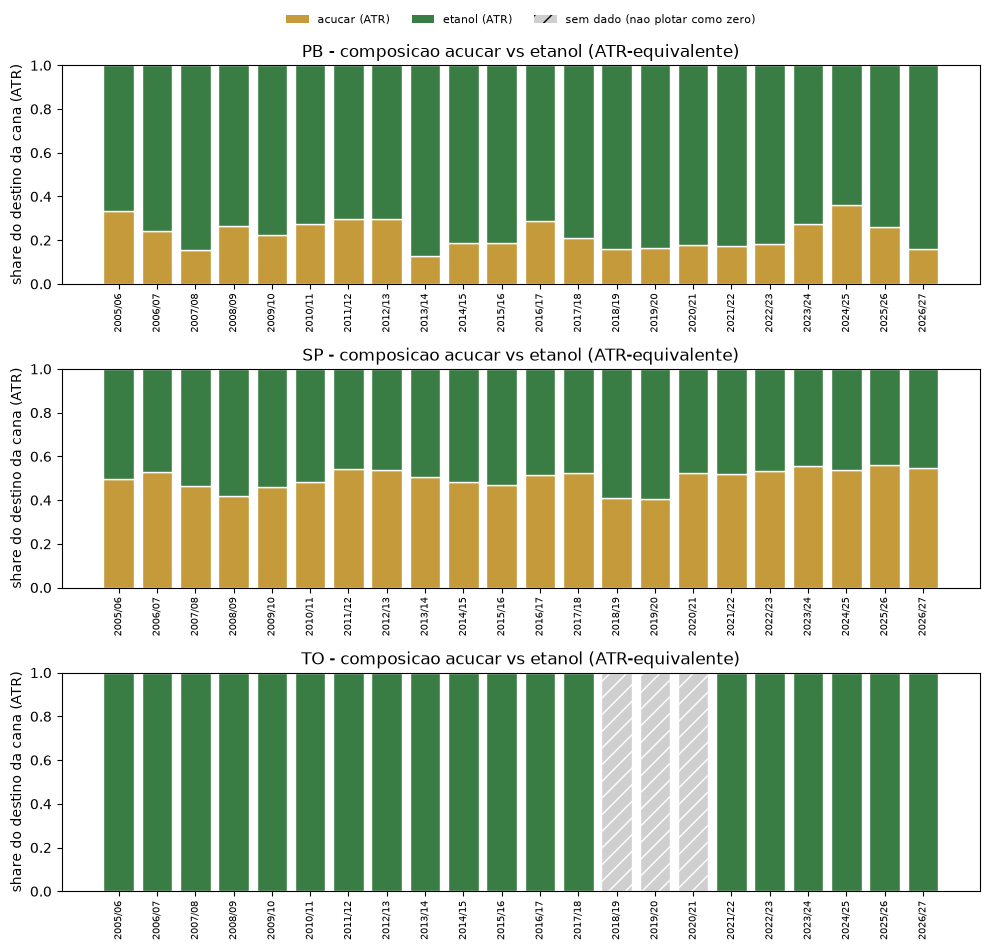

Share acucar (ATR) em 2023/24:
  PB: 27.54% acucar / 72.46% etanol  (situacao=presente)
  SP: 55.45% acucar / 44.55% etanol  (situacao=presente)
  TO: 0.00% acucar / 100.00% etanol  (situacao=mix_real)


In [16]:
# 6.4 (a) Composicao do destino da cana (share ATR) - barra empilhada 100% por safra.
# Convencao visual: 'sem dado' = hachura cinza (distinto de zero real); ADR 0008 no nivel visual.
COR_ACUCAR = "#c49a3a"   # acucar
COR_ETANOL = "#3a7d44"   # etanol
COR_SEMDADO = "#cfcfcf"  # sem dado (cinza)

def _serie_share(uf):
    s = ind[ind["uf"] == uf].sort_values("ano_alinhamento")
    return s

def plot_composicao_safra(uf, ax):
    s = _serie_share(uf)
    x = range(len(s))
    labels = s["safra"].tolist()
    for i, (_, r) in enumerate(s.iterrows()):
        if r["situacao_mix"] == "sem_dado" or pd.isna(r["share_acucar_atr"]):
            # Sem dado: barra inteira hachurada cinza, visualmente distinta de zero real.
            ax.bar(i, 1.0, color=COR_SEMDADO, hatch="//", edgecolor="white")
        else:
            sa = r["share_acucar_atr"]
            se = r["share_etanol_atr"]
            ax.bar(i, sa, color=COR_ACUCAR, edgecolor="white")
            ax.bar(i, se, bottom=sa, color=COR_ETANOL, edgecolor="white")
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_ylabel("share do destino da cana (ATR)")
    ax.set_title(f"{uf} - composicao acucar vs etanol (ATR-equivalente)")

ufs_contraste = ["PB", "SP", "TO"]  # PB foco; SP acucar-pesado; TO mono-etanol
fig, axes = plt.subplots(len(ufs_contraste), 1, figsize=(10, 3.2 * len(ufs_contraste)))
for ax, uf in zip(axes, ufs_contraste):
    plot_composicao_safra(uf, ax)
# Legenda unica
from matplotlib.patches import Patch
handles = [
    Patch(facecolor=COR_ACUCAR, label="acucar (ATR)"),
    Patch(facecolor=COR_ETANOL, label="etanol (ATR)"),
    Patch(facecolor=COR_SEMDADO, hatch="//", label="sem dado (nao plotar como zero)"),
]
axes[0].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.28),
               ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

# Numeros reais de referencia para o relatorio.
print("Share acucar (ATR) em 2023/24:")
for uf in ufs_contraste:
    r = ind[(ind["uf"] == uf) & (ind["safra"] == "2023/24")]
    if len(r):
        v = r.iloc[0]["share_acucar_atr"]
        print(f"  {uf}: {'INDEFINIDO' if pd.isna(v) else f'{v*100:.2f}% acucar / {(1-v)*100:.2f}% etanol'}"
              f"  (situacao={r.iloc[0]['situacao_mix']})")

### 6.5 (b) Volumes em base comparavel (por que ATR, e nao t vs L crus)

Empilhar **mil toneladas de acucar** com **mil litros de etanol** seria enganoso: sao unidades fisicas
diferentes, e a altura da barra dependeria da escolha arbitraria da escala. O grafico abaixo converte
**ambos para ATR-equivalente** (kg de ATR) antes de comparar. Agora a altura total e proporcional ao ATR
total reconstruido daquela UF-safra, e a reparticao interna (acucar vs etanol) e legitima. Safras "sem
dado" nao entram.

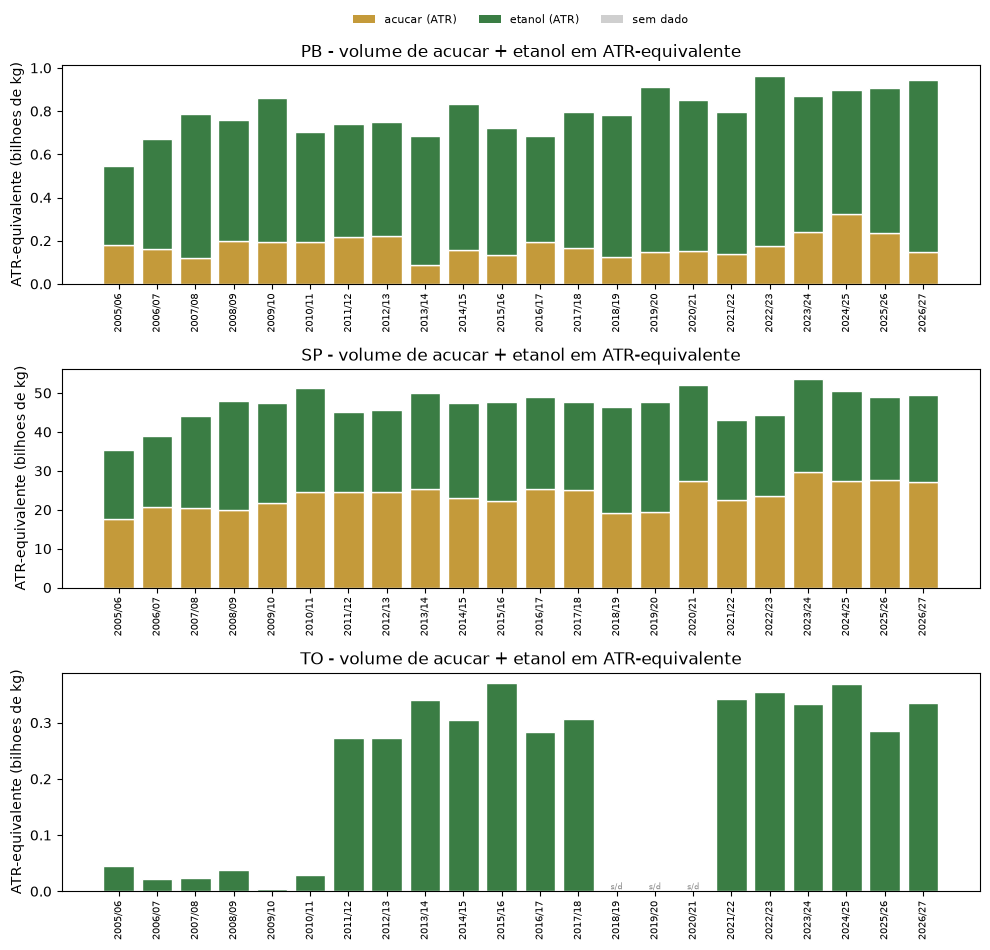

PB 2023/24 (ilustra por que converter):
  acucar  =        228.0 mil t   (unidade: toneladas)
  etanol  =    363,057.0 mil L   (unidade: litros)
  -> em ATR-equivalente:  acucar=0.239 bi kg | etanol=0.630 bi kg (mesma regua, comparavel)


In [17]:
# 6.5 (b) Volumes absolutos em ATR-equivalente (acucar + etanol empilhados na mesma regua).
def plot_volume_atr(uf, ax):
    s = _serie_share(uf)
    x = range(len(s))
    labels = s["safra"].tolist()
    for i, (_, r) in enumerate(s.iterrows()):
        aac, aet = r["atr_eq_acucar"], r["atr_eq_etanol"]
        if r["situacao_mix"] == "sem_dado" or pd.isna(aac) or pd.isna(aet):
            # Sem dado: marcador cinza na base (nao desenha volume inexistente).
            ax.bar(i, 0, color=COR_SEMDADO)
            ax.text(i, 0, "s/d", ha="center", va="bottom", fontsize=6, color="#888")
            continue
        # Em bilhoes de kg ATR para legibilidade.
        aac_b, aet_b = aac / 1e9, aet / 1e9
        ax.bar(i, aac_b, color=COR_ACUCAR, edgecolor="white")
        ax.bar(i, aet_b, bottom=aac_b, color=COR_ETANOL, edgecolor="white")
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_ylabel("ATR-equivalente (bilhoes de kg)")
    ax.set_title(f"{uf} - volume de acucar + etanol em ATR-equivalente")

fig, axes = plt.subplots(len(ufs_contraste), 1, figsize=(10, 3.2 * len(ufs_contraste)))
for ax, uf in zip(axes, ufs_contraste):
    plot_volume_atr(uf, ax)
axes[0].legend(handles=handles[:2] + [Patch(facecolor=COR_SEMDADO, label="sem dado")],
               loc="upper center", bbox_to_anchor=(0.5, 1.28), ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

# Demonstracao numerica de que t e L crus NAO sao comparaveis, mas ATR sim.
r = ind[(ind["uf"] == "PB") & (ind["safra"] == "2023/24")].iloc[0]
print("PB 2023/24 (ilustra por que converter):")
print(f"  acucar  = {r['producao_acucar_mil_t']:>12,.1f} mil t   (unidade: toneladas)")
print(f"  etanol  = {r['producao_etanol_total_mil_l']:>12,.1f} mil L   (unidade: litros)")
print(f"  -> em ATR-equivalente:  acucar={r['atr_eq_acucar']/1e9:.3f} bi kg | "
      f"etanol={r['atr_eq_etanol']/1e9:.3f} bi kg (mesma regua, comparavel)")

### 6.6 (c) Cana processada vs soma dos derivados (rendimento sem virar uma unica razao)

Comparacao pareada por safra: **entrou** X de cana (convertida a ATR pelo rendimento medio `atr_kg_t`,
que ja e kg de ATR por tonelada de cana) vs **saiu** Y de acucar + Z de etanol em ATR-equivalente
reconstruido dos volumes. Isso mostra o rendimento como **duas barras lado a lado**, nao como uma razao
unica — a perda entre a cana entrada e os derivados saidos fica visivel sem esconder as quantidades.

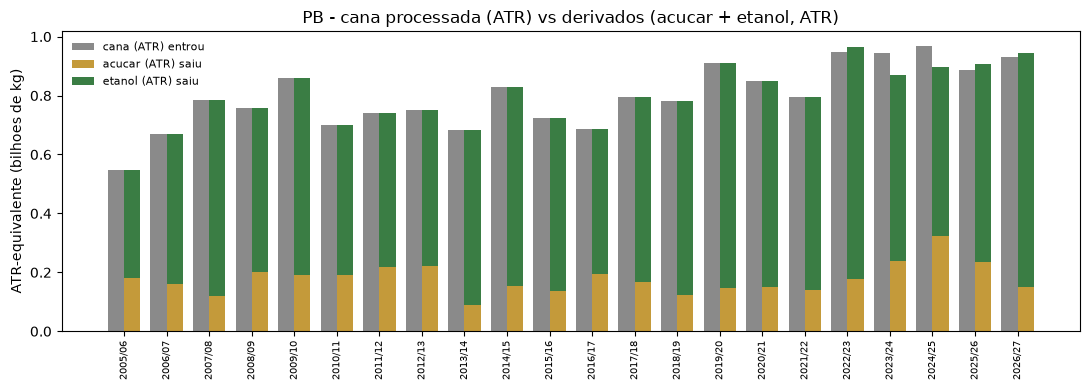

PB: aproveitamento ATR derivados/cana (recortes):
  2005/06: derivados/cana = 100.0% (nao e um unico numero global; varia por safra)
  2016/17: derivados/cana = 100.0% (nao e um unico numero global; varia por safra)
  2026/27: derivados/cana = 101.4% (nao e um unico numero global; varia por safra)


In [18]:
# 6.6 (c) Cana processada (ATR da cana) vs soma dos derivados (ATR reconstruido) - barras pareadas.
# ATR da cana = atr_kg_t (kg ATR/t) * cana (t). cana_mil_t -> t: *1e3.
def atr_da_cana(row):
    if pd.isna(row["atr_kg_t"]) or pd.isna(row["cana_mil_t"]) or row["cana_mil_t"] == 0:
        return np.nan
    return row["atr_kg_t"] * (row["cana_mil_t"] * 1e3)

uf = "PB"
s = _serie_share(uf).copy()
s["atr_cana"] = s.apply(atr_da_cana, axis=1)
s["atr_derivados"] = s["atr_eq_acucar"] + s["atr_eq_etanol"]

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(s))
w = 0.38
plotou_sd = False
for i, (_, r) in enumerate(s.iterrows()):
    if r["situacao_mix"] == "sem_dado" or pd.isna(r["atr_cana"]) or pd.isna(r["atr_derivados"]):
        ax.bar(i, 0, color=COR_SEMDADO)
        ax.text(i, 0, "s/d", ha="center", va="bottom", fontsize=6, color="#888")
        plotou_sd = True
        continue
    ax.bar(i - w / 2, r["atr_cana"] / 1e9, w, color="#8a8a8a", label="cana (ATR) entrou" if i == 0 else "")
    ax.bar(i + w / 2, r["atr_eq_acucar"] / 1e9, w, color=COR_ACUCAR,
           label="acucar (ATR) saiu" if i == 0 else "")
    ax.bar(i + w / 2, r["atr_eq_etanol"] / 1e9, w, bottom=r["atr_eq_acucar"] / 1e9,
           color=COR_ETANOL, label="etanol (ATR) saiu" if i == 0 else "")
ax.set_xticks(x)
ax.set_xticklabels(s["safra"], rotation=90, fontsize=7)
ax.set_ylabel("ATR-equivalente (bilhoes de kg)")
ax.set_title(f"{uf} - cana processada (ATR) vs derivados (acucar + etanol, ATR)")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

# Rendimento como numero, sem reduzir a uma unica razao global: eficiencia por safra.
_ok = s[s["situacao_mix"] != "sem_dado"].copy()
_ok["aproveitamento"] = _ok["atr_derivados"] / _ok["atr_cana"]
print(f"{uf}: aproveitamento ATR derivados/cana (recortes):")
for _, r in _ok.iloc[[0, len(_ok) // 2, -1]].iterrows():
    print(f"  {r['safra']}: derivados/cana = {r['aproveitamento']*100:.1f}% "
          f"(nao e um unico numero global; varia por safra)")

### 6.7 Normalizacao ATR correta e casos de borda

Ponto tecnico central: a coluna `atr_kg_t` da gold e o **rendimento medio** (kg de ATR por tonelada de
cana), **nao** o ATR total nem o ATR por produto. Ela nao pode ser usada para repartir acucar vs etanol.
Para o share do mix, reconstruimos o ATR-equivalente de **cada produto** a partir dos **volumes**, com os
fatores CONSECANA distintos (acucar 1,0495; etanol anidro 1,7651; hidratado 1,6913), e so entao dividimos.

**Casos de borda tratados:**

- **Mono-produto** (ex.: TO, so etanol): acucar=0 COM cana>0 -> share = **0% acucar / 100% etanol**. A
  soma fecha em 100% sem divisao por zero. Validado abaixo com TO 2023/24.
- **ATR reconstruido total = 0 ou insumos ausentes** (as 6 UF-safra com atr=0, ex.: RO 2019/20) ->
  **INDEFINIDO** (NaN), nunca 0% nem 50/50.
- **Todo `DIVIDE` protegido** contra denominador zero/nulo (`share_atr`).

In [19]:
# 6.7 Casos de borda da normalizacao ATR - asserts explicitos.
# Mono-produto TO 2023/24 -> 0% acucar, 100% etanol, soma 100%, sem divisao por zero.
r = ind[(ind["uf"] == "TO") & (ind["safra"] == "2023/24")].iloc[0]
assert r["share_acucar_atr"] == 0.0, r["share_acucar_atr"]
assert abs((r["share_acucar_atr"] + r["share_etanol_atr"]) - 1.0) < 1e-12
print(f"TO 2023/24 (mono-etanol): {r['share_acucar_atr']*100:.1f}% acucar / "
      f"{r['share_etanol_atr']*100:.1f}% etanol - soma 100%, sem div/0.")

# ATR total reconstruido zero / cana=0 -> INDEFINIDO para TODAS as 6 UF-safra com atr=0.
borda_atr0 = ind[ind["atr_kg_t"] == 0]
assert borda_atr0["share_acucar_atr"].isna().all(), "atr=0 deveria dar INDEFINIDO"
print(f"\n{len(borda_atr0)} UF-safra com ATR=0 -> share INDEFINIDO (NaN), nunca 0% nem 50/50:")
print("  " + ", ".join(f"{r.uf} {r.safra}" for r in borda_atr0.itertuples()))

# acucar NaN -> atr_eq_acucar NaN -> share INDEFINIDO (nunca fatia zero espuria).
borda_acnan = ind[ind["producao_acucar_mil_t"].isna()]
assert borda_acnan["share_acucar_atr"].isna().all()
print(f"\n{len(borda_acnan)} UF-safra com acucar NaN -> share INDEFINIDO (NaN).")

# Nenhum DIVIDE estourou: share so tem valores em [0,1] ou NaN.
val = ind["share_acucar_atr"].dropna()
assert ((val >= 0) & (val <= 1)).all()
print("\nTodos os shares validos estao em [0,1]; nenhum DIVIDE estourou em denominador zero.")

TO 2023/24 (mono-etanol): 0.0% acucar / 100.0% etanol - soma 100%, sem div/0.

6 UF-safra com ATR=0 -> share INDEFINIDO (NaN), nunca 0% nem 50/50:
  RO 2019/20, AC 2017/18, AC 2018/19, CE 2017/18, SC 2005/06, SC 2006/07

7 UF-safra com acucar NaN -> share INDEFINIDO (NaN).

Todos os shares validos estao em [0,1]; nenhum DIVIDE estourou em denominador zero.


### 6.8 Ressalva visual: "sem dado" distinto de zero real

Os graficos acima ja aplicam a distincao exigida pelo ADR 0008 **no nivel visual**:

- Num visual de **UFs ao longo do tempo** (6.4/6.5), a composicao so e desenhada onde ha dado; safras
  "sem dado" aparecem como **hachura cinza**, nunca como barra zerada — a nota de rodape reforca que uma
  lacuna **nao** deve ser lida como queda da producao.
- Num visual de **uma safra entre UFs** (abaixo), a barra "sem dado" e visualmente **distinta** de uma
  fatia zero legitima: cinza hachurado para ausencia, fatia cheia para o mix real (ex.: TO com acucar=0).

A celula abaixo materializa o corte de uma safra entre UFs com essa distincao.

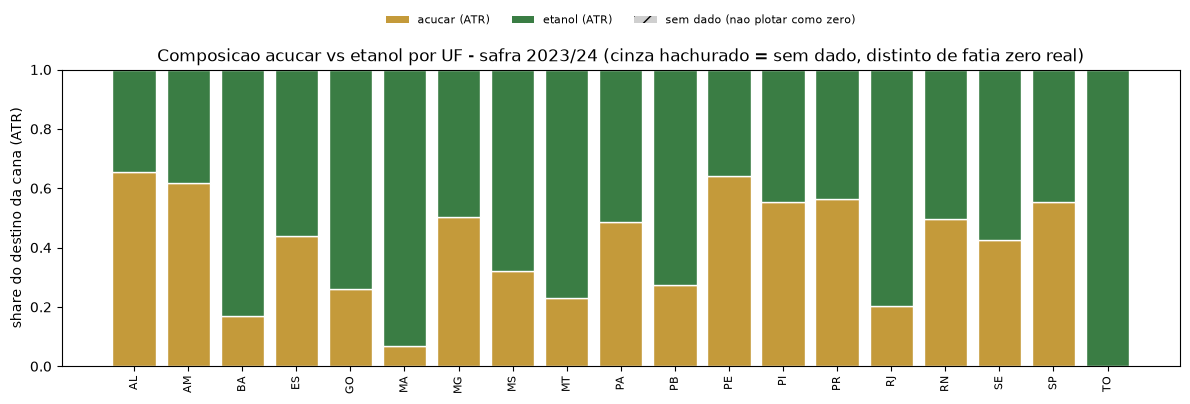

Safra 2023/24: 'sem dado' (hachura) = nenhuma
           'mix real' (fatia zero legitima, ex. so-etanol) = ['TO']
Nota: nos visuais de serie temporal, lacuna = sem dado, NAO queda de producao.


In [20]:
# 6.8 Corte de UMA safra entre UFs com 'sem dado' distinto de zero real.
SAFRA = "2023/24"
corte = ind[ind["safra"] == SAFRA].sort_values("uf").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, r in corte.iterrows():
    if r["situacao_mix"] == "sem_dado" or pd.isna(r["share_acucar_atr"]):
        ax.bar(i, 1.0, color=COR_SEMDADO, hatch="//", edgecolor="white")
    else:
        sa, se = r["share_acucar_atr"], r["share_etanol_atr"]
        ax.bar(i, sa, color=COR_ACUCAR, edgecolor="white")
        ax.bar(i, se, bottom=sa, color=COR_ETANOL, edgecolor="white")
ax.set_xticks(range(len(corte)))
ax.set_xticklabels(corte["uf"], rotation=90, fontsize=8)
ax.set_ylim(0, 1)
ax.set_ylabel("share do destino da cana (ATR)")
ax.set_title(f"Composicao acucar vs etanol por UF - safra {SAFRA} "
             "(cinza hachurado = sem dado, distinto de fatia zero real)")
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.22),
          ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

semdado = corte.loc[corte["situacao_mix"] == "sem_dado", "uf"].tolist()
mixreal = corte.loc[corte["situacao_mix"] == "mix_real", "uf"].tolist()
print(f"Safra {SAFRA}: 'sem dado' (hachura) = {semdado or 'nenhuma'}")
print(f"           'mix real' (fatia zero legitima, ex. so-etanol) = {mixreal or 'nenhuma'}")
print("Nota: nos visuais de serie temporal, lacuna = sem dado, NAO queda de producao.")

### 6.9 Comparacao em dois eixos e critica as razoes existentes

**Dois eixos de leitura** (com numeros reais, abaixo):

1. **PB vs outras UFs** numa safra: a PB destina ~27,5% da cana (em ATR) ao acucar em 2023/24, bem abaixo
   de SP (~55%) e AL (~66%); e um perfil mais inclinado ao etanol que a media canavieira do Sudeste.
2. **PB ao longo das safras**: a serie de share mostra como esse equilibrio se moveu, sem a lacuna
   espuria que um `NaN->0` criaria.

**Por que a visao de volume complementa (nao substitui) as razoes existentes.** O modelo ja tem tres
indicadores de razao no nivel UF (`fato_industria`), todos corretos mas que **comprimem** a informacao:

| Indicador (DAX real) | O que diz | Limite |
|---|---|---|
| `Mix etanol acucar (L por t)` = DIVIDE(Σ etanol_total, Σ acucar) | litros de etanol por tonelada de acucar | estoura/indefine quando acucar->0 (mono-etanol); esconde o tamanho |
| `Intensidade acucar (t por t)` = DIVIDE(Σ acucar, Σ cana) | fracao da cana que virou acucar (em massa) | ignora o etanol; nao e base comum |
| `ATR ponderado (kg por t)` = DIVIDE(Σ(atr·cana), Σ cana) | rendimento medio ponderado | rendimento, nao composicao; nao reparte acucar/etanol |

Uma razao responde "quanto de A por B"; o **share em ATR** responde "deste total, que fracao foi cada
produto" — some para 100%, trata mono-produto sem estourar, e e a unica das quatro que poe acucar e
etanol na **mesma regua**. As duas visoes sao complementares.

**Fundamentacao.** O ATR/CONSECANA e o padrao setorial brasileiro de base comum para acucar e etanol
([CONSECANA-SP](https://www.consecana.com.br/); fatores em
[Piracicaba Engenharia](https://www.piracicabaengenharia.com.br/resumo-das-formulas-de-rendimentos-e-eficiencia-utilizadas-na-industria-acucareira/);
contexto de ATR por estado em [novaCana](https://data.novacana.com/indicadores/atr-mapa)). A serie
historica de acucar/etanol/ATR por UF-safra vem da
[CONAB — Serie Historica da Cana](https://portaldeinformacoes.conab.gov.br/downloads/arquivos/SerieHistoricaCana.txt).
Share/composicao como medida de mix (em vez de razao unitaria) e estatistica descritiva padrao de
participacao. *Conteudo das fontes parafraseado para conformidade de licenciamento.*

> **Escopo (ADR 0002):** estes indicadores so existem no nivel UF — a CONAB nao desce a municipio nem
> microrregiao. Como so ha um nivel, a secao de volume/mix nao sofre a ambiguidade de filtro de nivel
> que motiva o Bloco D.

In [21]:
# 6.9 Numeros reais dos dois eixos (PB entre UFs; PB ao longo do tempo).
SAFRA = "2023/24"
corte = ind[(ind["safra"] == SAFRA) & (ind["situacao_mix"] != "sem_dado")].copy()
corte = corte.sort_values("share_acucar_atr", ascending=False)
print(f"Eixo 1 - share acucar (ATR) por UF, safra {SAFRA} (maior = mais acucareiro):")
for _, r in corte.iterrows():
    print(f"  {r['uf']:3s} {r['share_acucar_atr']*100:5.1f}% acucar / "
          f"{r['share_etanol_atr']*100:5.1f}% etanol")

pb = ind[ind["uf"] == "PB"].sort_values("ano_alinhamento")
print(f"\nEixo 2 - PB share acucar (ATR) ao longo das safras (recortes):")
for _, r in pb.iloc[[0, len(pb) // 2, -1]].iterrows():
    print(f"  {r['safra']}: {r['share_acucar_atr']*100:.1f}% acucar / "
          f"{r['share_etanol_atr']*100:.1f}% etanol")
_pb23 = pb[pb["safra"] == "2023/24"].iloc[0]
print(f"\nReferencia p/ relatorio: PB 2023/24 share acucar (ATR) = "
      f"{_pb23['share_acucar_atr']*100:.2f}%  (SP {corte[corte.uf=='SP'].iloc[0]['share_acucar_atr']*100:.1f}%, "
      f"AL {corte[corte.uf=='AL'].iloc[0]['share_acucar_atr']*100:.1f}%, TO 0%).")

Eixo 1 - share acucar (ATR) por UF, safra 2023/24 (maior = mais acucareiro):
  AL   65.5% acucar /  34.5% etanol
  PE   64.0% acucar /  36.0% etanol
  AM   61.9% acucar /  38.1% etanol
  PR   56.2% acucar /  43.8% etanol
  PI   55.5% acucar /  44.5% etanol
  SP   55.4% acucar /  44.6% etanol
  MG   50.3% acucar /  49.7% etanol
  RN   49.5% acucar /  50.5% etanol
  PA   48.8% acucar /  51.2% etanol
  ES   43.8% acucar /  56.2% etanol
  SE   42.5% acucar /  57.5% etanol
  MS   32.0% acucar /  68.0% etanol
  PB   27.5% acucar /  72.5% etanol
  GO   26.0% acucar /  74.0% etanol
  MT   23.0% acucar /  77.0% etanol
  RJ   20.3% acucar /  79.7% etanol
  BA   16.8% acucar /  83.2% etanol
  MA    6.8% acucar /  93.2% etanol
  TO    0.0% acucar / 100.0% etanol

Eixo 2 - PB share acucar (ATR) ao longo das safras (recortes):
  2005/06: 33.1% acucar / 66.9% etanol
  2016/17: 28.6% acucar / 71.4% etanol
  2026/27: 15.8% acucar / 84.2% etanol

Referencia p/ relatorio: PB 2023/24 share acucar (ATR) = 

## 7. Arquitetura: eliminar o filtro de nivel territorial (Bloco D)

**O pedido.** A colega Alex pediu para "rever a modelagem dos dados para nao precisar aplicar o filtro de
nivel territorial nas paginas do Power BI". Hoje cada pagina precisa fixar manualmente `nivel_territorial`
(uf / microrregiao / municipio) para nao misturar niveis. Esta secao diagnostica **por que** e propoe
duas arquiteturas, recomendando uma. Nada aqui e aplicado ao modelo — e proposta para o relatorio.

### 7.1 Diagnostico: por que o filtro manual e necessario hoje

`fato_producao` **empilha os tres niveis na mesma tabela** (municipio, microrregiao, uf), e esses niveis
sao **totais sobrepostos do mesmo fenomeno**: a producao de um municipio da PB ja esta contida na
microrregiao, que ja esta contida no total da UF. Somar mais de um nivel **conta a mesma cana varias
vezes**.

Evidencia numerica (reproduzida no Bloco B e confirmada abaixo): somando **todos os niveis** de 2023
(uf + microrregiao PB + municipio PB) chega-se a **101,8% do total verdadeiro das UFs** — passa de 100%
exatamente porque micro e municipio repetem producao ja contida no total UF. Por isso toda medida que nao
fixa o nivel ou vira BLANK (as medidas se protegem com `HASONEVALUE`/`SELECTEDVALUE`) ou, num visual mal
configurado, soma lixo.

As medidas em si estao **corretas** (Bloco B): elas se defendem retornando BLANK fora de um nivel unico.
O problema e de **modelagem/experiencia**: o autor da pagina precisa lembrar de fixar o nivel toda vez.

In [22]:
# 7.1 Evidencia da sobreposicao de niveis (reproduz os 101,8%). Nao altera a gold.
ANO = 2023
fp = fato_producao
uf_total = fp[(fp[NIVEL] == "uf") & (fp["ano_referencia"] == ANO)][Q].sum()
# PB nos tres niveis (micro e municipio PB repetem a producao ja contida no total UF).
pb_micro = fp[(fp[NIVEL] == "microrregiao") & (fp["ano_referencia"] == ANO)
              & (fp["territorio_id"].str.startswith("micro"))]
# A PB como UF: usar o total de micro/municipio da PB (coincidem com a PB-UF).
pb_uf = fp[(fp[NIVEL] == "uf") & (fp["ano_referencia"] == ANO) & (fp["territorio_id"] == "uf:25")][Q].sum()
# Soma cega dos tres niveis = total UF + micro PB + municipio PB (os dois ultimos duplicam a PB).
micro_pb = fp[(fp[NIVEL] == "microrregiao") & (fp["ano_referencia"] == ANO)][Q].sum()
mun_pb = fp[(fp[NIVEL] == "municipio") & (fp["ano_referencia"] == ANO)][Q].sum()
soma_cega = uf_total + micro_pb + mun_pb
print(f"Total verdadeiro (nivel uf, {ANO})      = {uf_total:,.0f} t")
print(f"Soma cega dos 3 niveis ({ANO})           = {soma_cega:,.0f} t")
print(f"Soma cega / total verdadeiro            = {soma_cega / uf_total * 100:.1f}%  (deveria ser 100%)")
print(f"PB (uf:25) {ANO}                          = {pb_uf:,.0f} t  = micro PB = municipio PB (mesmo fenomeno)")
assert round(soma_cega / uf_total * 100, 1) == 101.8, soma_cega / uf_total * 100
print("\nConfirma: misturar niveis duplica producao -> dai a necessidade do filtro de nivel manual.")

Total verdadeiro (nivel uf, 2023)      = 782,058,236 t
Soma cega dos 3 niveis (2023)           = 796,191,840 t
Soma cega / total verdadeiro            = 101.8%  (deveria ser 100%)
PB (uf:25) 2023                          = 7,066,802 t  = micro PB = municipio PB (mesmo fenomeno)

Confirma: misturar niveis duplica producao -> dai a necessidade do filtro de nivel manual.


### 7.2 Opcoes de arquitetura (proposta, nao aplicada)

**Opcao A — separar os fatos por nivel / camada semantica.** Em vez de uma tabela `fato_producao` com os
tres niveis empilhados, materializar (ou expor na camada semantica) **um fato por nivel**:
`fato_producao_uf`, `fato_producao_microrregiao`, `fato_producao_municipio`. Cada pagina consome o fato do
seu nivel; nao existe mais mistura possivel, logo **o filtro de nivel desaparece**.

- *Pros:* elimina a sobreposicao na raiz; cada visual e matematicamente seguro sem depender de o autor
  lembrar de filtrar; totais sempre fecham em 100%. Alinha-se ao fato de o painel ser majoritariamente
  nivel UF (PB vs UFs), inclusive a nova secao de volume/mix, que e **so-UF** por origem (CONAB, ADR 0002).
- *Contras:* exige mudar o pipeline/gold (ou a camada de modelo) para produzir fatos separados; relacoes e
  medidas precisam ser reescritas por fato; mais objetos no modelo.

**Opcao B — medidas cientes de nivel (level-aware).** Manter a tabela empilhada, mas embutir em TODA medida
a logica de so agregar o nivel corrente (via `HASONEVALUE`/`TREATAS`/`ISINSCOPE`), e padronizar visuais para
sempre carregarem o nivel no contexto.

- *Pros:* nao mexe na gold nem no pipeline; mudanca contida nas medidas.
- *Contras:* o risco continua latente (um visual novo que esqueca o nivel volta a somar lixo); a defesa fica
  espalhada em cada medida, dificil de auditar; nao remove o filtro — apenas o automatiza parcialmente.

**Recomendacao: Opcao A (fatos separados por nivel).** O dashboard e, na pratica, "**PB vs outras UFs**":
a maioria das paginas vive no nivel UF, e os indicadores industriais de volume/mix (Bloco C) sao so-UF por
construcao. Separar os fatos remove a sobreposicao na origem, elimina de fato o filtro de nivel (o pedido da
Alex) e torna cada pagina segura por padrao, em vez de segura so se o autor lembrar de filtrar. A Opcao B e
um paliativo aceitavel se nao for possivel tocar o pipeline agora, mas nao resolve a causa-raiz.

> **Lembrete de escopo desta rodada:** nenhuma das opcoes foi aplicada. Isto e PROPOSTA para o relatorio
> (`auditoria-medidas-dax.md`); a decisao e dos donos do modelo apos a leitura.

## Encerramento (FEAT-002)

Esta rodada acrescentou ao notebook o **Bloco C** (indicadores de volume e composicao do mix via
ATR-equivalente) e o **Bloco D** (arquitetura do filtro de nivel):

- **Bloco C** compara **visualmente as quantidades** de acucar, etanol e cana sem reduzir a uma razao
  unitaria, usando ATR-equivalente com fatores CONSECANA **distintos** (acucar 1,0495 — premissa branco
  vs VHP marcada "a confirmar"; etanol anidro 1,7651 / hidratado 1,6913, sempre separados). A sub-secao de
  **cobertura e ausencia vem antes dos visuais**, com a convencao `zero != ausente` (ADR 0008): mono-produto
  (TO) aparece como **100%/0%**, e cana=0 / atr=0 / acucar-NaN aparecem como **"sem dado"** (nunca 0% nem
  50/50), com contagem de UFs por situacao e safra. A **ressalva visual** distingue "sem dado" (hachura
  cinza) de zero real nos graficos. Numeros-chave: **PB 2023/24 share acucar (ATR) = 27,5%** (SP ~55%, AL
  ~66%, TO 0%).
- **Bloco D** diagnostica que `fato_producao` empilha tres niveis sobrepostos (soma cega = **101,8%** do
  total verdadeiro) e recomenda a **Opcao A** (separar fatos por nivel) para eliminar o filtro de nivel,
  por o dashboard ser majoritariamente "PB vs UFs".

**Nenhum ajuste foi aplicado ao modelo Power BI.** Fatores ATR, indicadores de volume/mix e a mudanca de
arquitetura sao PROPOSTAS para o relatorio (`auditoria-medidas-dax.md`), marcadas "sugestao, nao aplicada".